# Sprint 1 - Notebook de EDA

Este notebook cubre el análisis exploratorio inicial del dataset de triatlón masculino 2025.

Objetivos:
- Ver tamaños, tipos y calidad básica de los datos.
- Revisar nulos por columna.
- Analizar la distribución del tiempo final y de variables relevantes.
- Detectar posibles outliers y atletas con poca participación.
- Comprobar si existe información útil para etiquetar `descalificado`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')

def find_workspace_root() -> Path:
    override = os.environ.get('CONERSYS_WORKSPACE')
    if override:
        override_path = Path(override).expanduser()
        if (override_path / 'data' / 'processed').exists():
            return override_path
    candidates = [Path.cwd(), *Path.cwd().parents]
    candidates.extend([Path('/workspaces'), Path('/workspace'), Path('/home/oai/workspace'), Path('/mnt/data'), Path('/data'), Path('/content')])
    for base in candidates:
        if not base.exists():
            continue
        direct = base / 'data' / 'processed'
        if (direct / 'deportistas_2025.csv').exists() and (direct / 'pruebas_2025.csv').exists():
            return base
        if base.is_dir():
            for child in base.iterdir():
                if not child.is_dir():
                    continue
                nested = child / 'data' / 'processed'
                if (nested / 'deportistas_2025.csv').exists() and (nested / 'pruebas_2025.csv').exists():
                    return child
    return Path.cwd()

WORKSPACE = find_workspace_root()
DATA_DIR = WORKSPACE / 'data' / 'processed'

PATH_DEPORTISTAS = DATA_DIR / 'deportistas_2025.csv'
PATH_PRUEBAS = DATA_DIR / 'pruebas_2025.csv'
PATH_CLUBES = DATA_DIR / 'clubes_geo_2025.csv'
PATH_RESULTADOS = DATA_DIR / 'resultados_2025.csv'

print('Rutas preparadas correctamente')
print(PATH_DEPORTISTAS)
print(PATH_PRUEBAS)
print(PATH_CLUBES)
print(PATH_RESULTADOS)
print('Existe deportistas:', PATH_DEPORTISTAS.exists())
print('Existe pruebas:', PATH_PRUEBAS.exists())
print('Existe clubes:', PATH_CLUBES.exists())
print('Existe resultados:', PATH_RESULTADOS.exists())

Rutas preparadas correctamente
c:\Users\mario\PycharmProjects\conersys_predictivo_triatlon_elitemasculino\data\processed\deportistas_2025.csv
c:\Users\mario\PycharmProjects\conersys_predictivo_triatlon_elitemasculino\data\processed\pruebas_2025.csv
c:\Users\mario\PycharmProjects\conersys_predictivo_triatlon_elitemasculino\data\processed\clubes_geo_2025.csv
c:\Users\mario\PycharmProjects\conersys_predictivo_triatlon_elitemasculino\data\processed\resultados_2025.csv
Existe deportistas: True
Existe pruebas: True
Existe clubes: True
Existe resultados: True


## 1. Carga de datos

Trabajamos sobre los ficheros procesados del sprint anterior para entender su calidad antes de construir features o modelos.

In [2]:
required_paths = {
    'deportistas': PATH_DEPORTISTAS,
    'pruebas': PATH_PRUEBAS,
    'clubes': PATH_CLUBES,
    'resultados': PATH_RESULTADOS,
}

missing = [f'{name}: {path}' for name, path in required_paths.items() if not path.exists()]
DATA_AVAILABLE = len(missing) == 0

if DATA_AVAILABLE:
    df_deportistas = pd.read_csv(PATH_DEPORTISTAS)
    df_pruebas = pd.read_csv(PATH_PRUEBAS)
    df_clubes = pd.read_csv(PATH_CLUBES)
    df_resultados = pd.read_csv(PATH_RESULTADOS)
    print('Deportistas:', df_deportistas.shape)
    print('Pruebas:', df_pruebas.shape)
    print('Clubes:', df_clubes.shape)
    print('Resultados:', df_resultados.shape)
else:
    df_deportistas = pd.DataFrame()
    df_pruebas = pd.DataFrame()
    df_clubes = pd.DataFrame()
    df_resultados = pd.DataFrame()
    print('No se han encontrado los CSV procesados necesarios para el EDA.')
    print('Define la variable de entorno CONERSYS_WORKSPACE apuntando a la raíz del proyecto o monta el directorio data/processed.')
    print('Faltan:')
    for item in missing:
        print(f'- {item}')

Deportistas: (1028, 4)
Pruebas: (128, 14)
Clubes: (476, 5)
Resultados: (1525, 6)


In [24]:
if DATA_AVAILABLE:
    print('--- Esquema de df_resultados ---')
    print(list(df_resultados.columns))
    print()
    print('--- Esquema de df_pruebas ---')
    print(list(df_pruebas.columns))
    print()
    print('--- Esquema de df_deportistas ---')
    print(list(df_deportistas.columns))
    print()

    # Objetivo del modelo: usar el dataset de entrenamiento como referencia explícita
    if 'PUNTOS_TARGET' in df_train.columns:
        MODEL_TARGET_COL = 'PUNTOS_TARGET'
    elif 'PUESTO_TARGET' in df_train.columns:
        MODEL_TARGET_COL = 'PUESTO_TARGET'
    elif 'puntos' in df_resultados.columns:
        MODEL_TARGET_COL = 'puntos'
    elif 'puesto' in df_resultados.columns:
        MODEL_TARGET_COL = 'puesto'
    else:
        MODEL_TARGET_COL = None
    print('MODEL_TARGET_COL:', MODEL_TARGET_COL)

    # Mapeo real de claves de unión tras normalizar nombres
    join_key_map = []
    if 'deportista_documento' in df_resultados.columns and 'DOCUMENTO' in df_deportistas.columns:
        join_key_map.append(('deportista_documento', 'DOCUMENTO'))
    if 'prueba_id' in df_resultados.columns and 'id' in df_pruebas.columns:
        join_key_map.append(('prueba_id', 'id'))
    print('Mapeo de claves de unión detectado:', join_key_map)
else:
    MODEL_TARGET_COL = None
    join_key_map = []


--- Esquema de df_resultados ---
['season', 'ranking_type_id', 'deportista_documento', 'prueba_id', 'puntos', 'puesto']

--- Esquema de df_pruebas ---
['id', 'season', 'nombre', 'championship_level', 'fecha', 'ciudad', 'provincia', 'lat', 'lng', 'altitud', 'temperatura_max', 'humedad_media', 'precipitacion', 'viento_max']

--- Esquema de df_deportistas ---
['DOCUMENTO', 'NOMBRE', 'CLUB', 'GGEE']

MODEL_TARGET_COL: PUNTOS_TARGET
Mapeo de claves de unión detectado: [('deportista_documento', 'DOCUMENTO'), ('prueba_id', 'id')]


## 2.1. Cruce de tablas para análisis multivariable

Antes de interpretar variables aisladas, conviene unir resultados, pruebas y deportistas para ver cómo se comportan las variables del evento y del atleta en conjunto.

Shape resultados: (1525, 6)
Shape pruebas: (128, 14)
Shape deportistas: (1028, 4)
Shape merged_full: (1525, 22)

Cobertura de join con pruebas (PRUEBA_ID): 100.0
Cobertura de join con deportistas (DOCUMENTO): 100.0

Target para el análisis cruzado: puntos
Referencia del dataset de entrenamiento: PUNTOS_TARGET


count    1525.000000
mean      189.519951
std       311.152112
min         0.519694
25%         0.817220
50%        29.695016
75%       245.782631
max      2000.000000
Name: puntos, dtype: float64

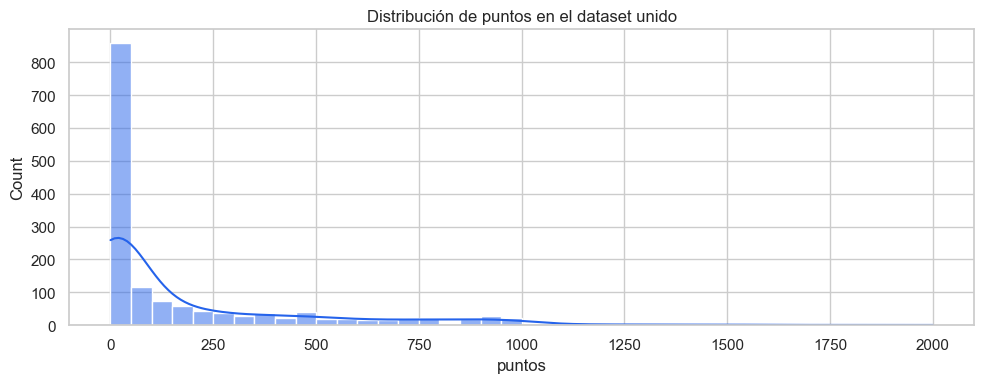

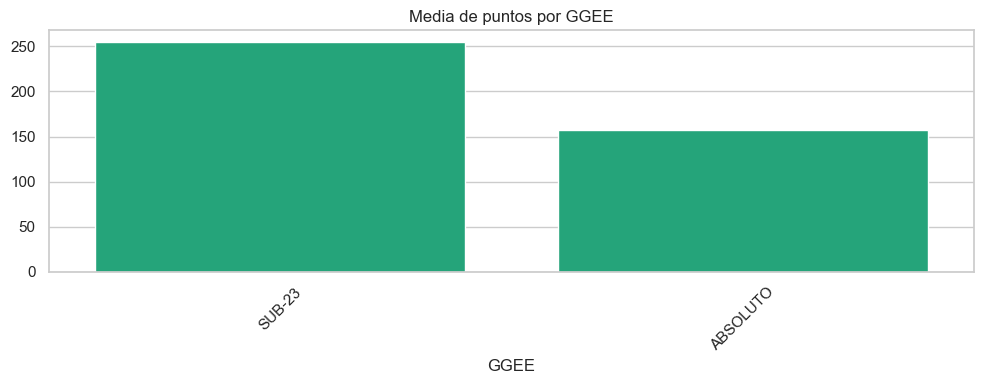

C:\Users\mario\AppData\Local\Temp\ipykernel_3928\4011109691.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=merged_full, x='championship_level', y=target_col, palette='Set2')


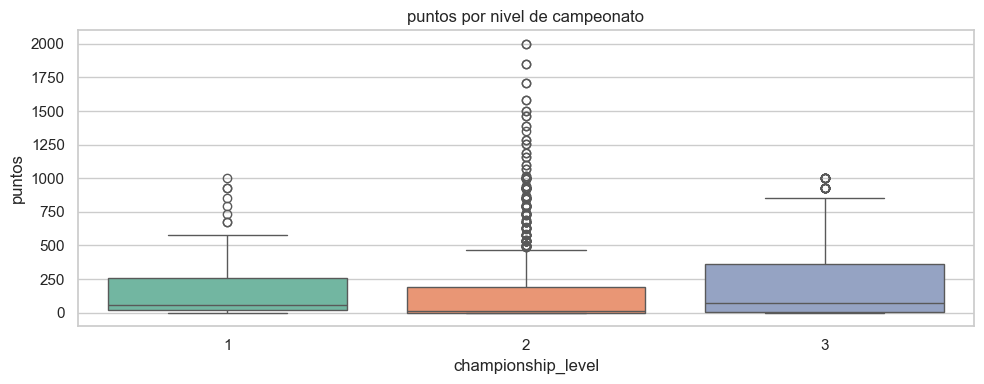

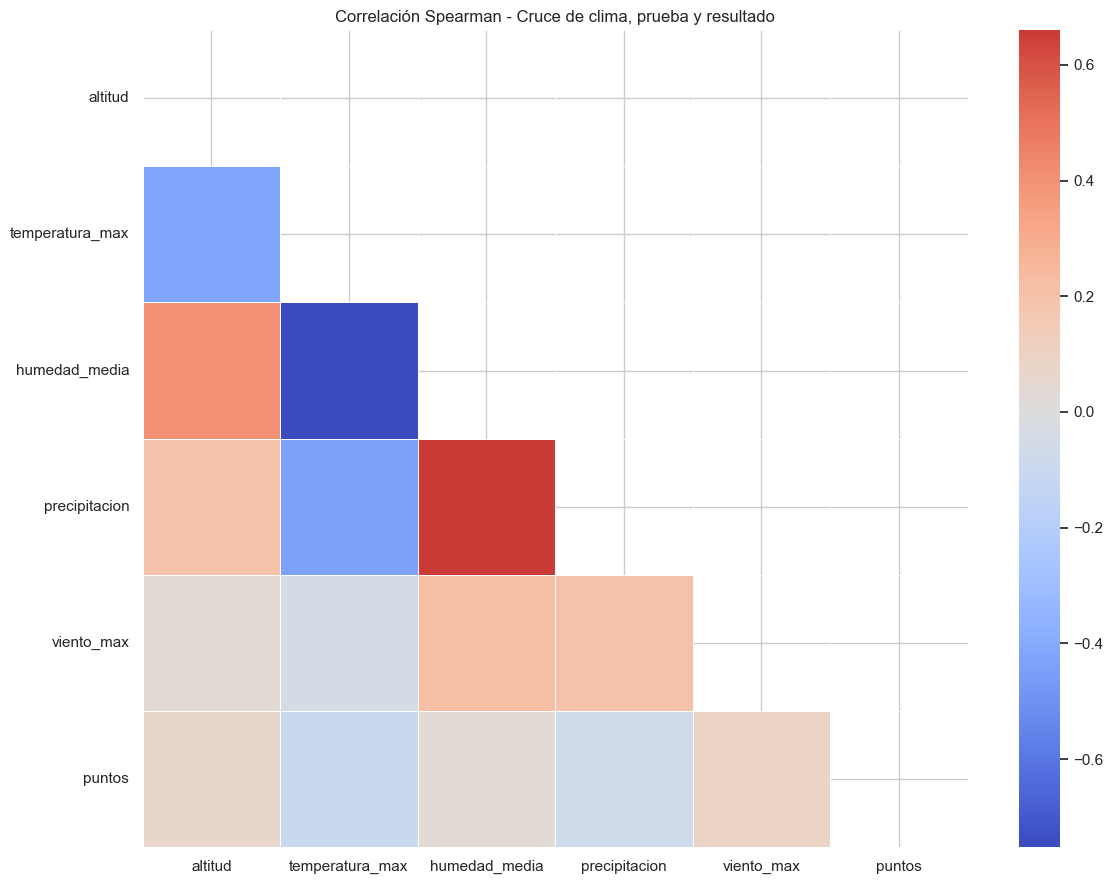

Pares con |spearman| >= 0.5 (ordenados):


temperatura_max  humedad_media    0.751301
humedad_media    precipitacion    0.659448
dtype: float64

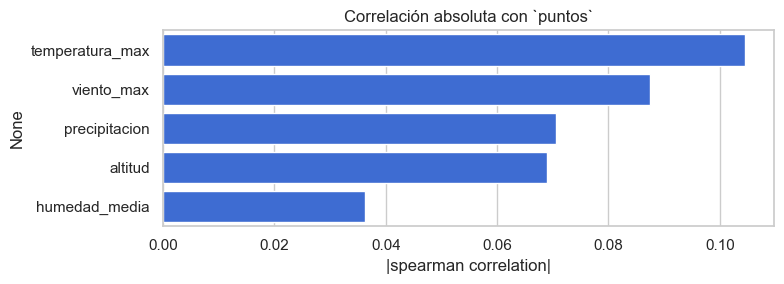

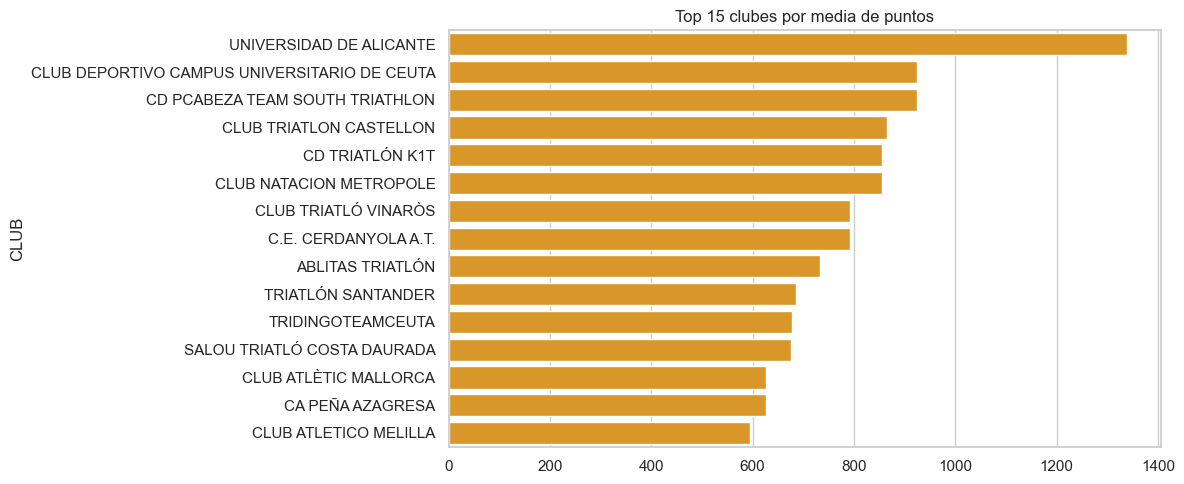

In [21]:
if DATA_AVAILABLE:
    resultados_join = df_resultados.rename(columns={'deportista_documento': 'DOCUMENTO', 'prueba_id': 'PRUEBA_ID'}).copy()
    pruebas_join = df_pruebas.rename(columns={'id': 'PRUEBA_ID'}).copy()
    deportistas_join = df_deportistas.rename(columns={'DOCUMENTO': 'DOCUMENTO'}).copy()

    merged_full = resultados_join.merge(pruebas_join, on='PRUEBA_ID', how='left', suffixes=('', '_prueba'))
    merged_full = merged_full.merge(deportistas_join, on='DOCUMENTO', how='left', suffixes=('', '_deportista'))

    print('Shape resultados:', df_resultados.shape)
    print('Shape pruebas:', df_pruebas.shape)
    print('Shape deportistas:', df_deportistas.shape)
    print('Shape merged_full:', merged_full.shape)
    print()

    print('Cobertura de join con pruebas (PRUEBA_ID):', round(merged_full['season_prueba'].notna().mean() * 100, 2) if 'season_prueba' in merged_full.columns else 'N/A')
    print('Cobertura de join con deportistas (DOCUMENTO):', round(merged_full['NOMBRE'].notna().mean() * 100, 2) if 'NOMBRE' in merged_full.columns else 'N/A')
    print()

    # En el cruce raw el target útil es el que sí existe en el dataframe unido.
    if 'puntos' in merged_full.columns:
        target_col = 'puntos'
    elif 'puesto' in merged_full.columns:
        target_col = 'puesto'
    else:
        target_col = None
    print('Target para el análisis cruzado:', target_col)
    if 'PUNTOS_TARGET' in df_train.columns:
        print('Referencia del dataset de entrenamiento:', 'PUNTOS_TARGET')
    elif 'PUESTO_TARGET' in df_train.columns:
        print('Referencia del dataset de entrenamiento:', 'PUESTO_TARGET')

    if target_col is not None and target_col in merged_full.columns:
        display(merged_full[target_col].describe())
        plt.figure(figsize=(10, 4))
        sns.histplot(merged_full[target_col].dropna(), bins=40, kde=True, color='#2563eb')
        plt.title(f'Distribución de {target_col} en el dataset unido')
        plt.tight_layout()
        plt.show()

        if 'GGEE' in merged_full.columns:
            ggee_target = merged_full.groupby('GGEE')[target_col].mean().sort_values(ascending=False)
            plt.figure(figsize=(10, 4))
            sns.barplot(x=ggee_target.index.astype(str), y=ggee_target.values, color='#10b981')
            plt.title(f'Media de {target_col} por GGEE')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

        if 'championship_level' in merged_full.columns:
            plt.figure(figsize=(10, 4))
            sns.boxplot(data=merged_full, x='championship_level', y=target_col, palette='Set2')
            plt.title(f'{target_col} por nivel de campeonato')
            plt.tight_layout()
            plt.show()

        climate_cols = [c for c in ['altitud', 'temperatura_max', 'humedad_media', 'precipitacion', 'viento_max'] if c in merged_full.columns]
        if climate_cols:
            plot_correlation_heatmap(merged_full, climate_cols + [target_col], 'Cruce de clima, prueba y resultado', method='spearman', top_pairs_threshold=0.5)

        if 'CLUB' in merged_full.columns:
            club_target = merged_full.groupby('CLUB')[target_col].mean().sort_values(ascending=False).head(15)
            plt.figure(figsize=(12, 5))
            sns.barplot(x=club_target.values, y=club_target.index, color='#f59e0b')
            plt.title(f'Top 15 clubes por media de {target_col}')
            plt.tight_layout()
            plt.show()
    else:
        print('No se pudo identificar una columna objetivo para el cruce.')
else:
    print('No hay datos cargados para el cruce multivariable.')

In [ ]:
def plot_correlation_heatmap(df: pd.DataFrame, cols: list[str], title: str, method: str = 'spearman', top_pairs_threshold: float = 0.6) -> None:
    """Muestra una matriz de correlación mejorada y más legible.
    Mejoras en caso de 2 variables: annot, formato, ticks y scatter con ejes claros.
    """
    cols = [c for c in cols if c in df.columns]
    if len(cols) < 2:
        print(f'No hay suficientes columnas para correlación en {title}')
        return

    # eliminar columnas casi constantes
    filtered = []
    for c in cols:
        try:
            if df[c].dropna().nunique() <= 2:
                continue
            if df[c].dtype == 'object' and df[c].nunique(dropna=True) > 50:
                continue
        except Exception:
            continue
        filtered.append(c)

    if len(filtered) < 2:
        print(f'Después del filtrado no quedan columnas útiles para correlación en {title}')
        return

    max_vars = 40
    if len(filtered) > max_vars:
        if 'puntos' in df.columns:
            base = [c for c in filtered if c != 'puntos']
            corr_with_target = df[base].corrwith(df['puntos'], method=method).abs().sort_values(ascending=False)
            top = corr_with_target.head(max_vars - 1).index.tolist()
            filtered = ['puntos'] + top
        else:
            vars_by_var = pd.Series({c: df[c].dropna().var() for c in filtered}).sort_values(ascending=False)
            filtered = vars_by_var.head(max_vars).index.tolist()

    corr = df[filtered].corr(method=method)

    # Caso especial: solo 2 variables -> heatmap anotada + scatter más legible
    if corr.shape[0] == 2:
        try:
            plt.figure(figsize=(6, 5))
            sns.heatmap(corr, annot=True, cmap='vlag', center=0, fmt='.3f', cbar=True, vmin=-1, vmax=1, square=True, linewidths=0.5)
            plt.title(f'Correlación {method.capitalize()} - {title}')
            plt.xticks(rotation=45, ha='right')
            plt.yticks(rotation=0)
            plt.tight_layout()
            plt.show()
        except Exception:
            pass

        vars2 = list(corr.columns)
        xvar, yvar = vars2[0], vars2[1]
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df, x=xvar, y=yvar, alpha=0.4)
        try:
            sns.regplot(data=df, x=xvar, y=yvar, scatter=False, line_kws={'color':'red'})
        except Exception:
            pass
        plt.xlabel(xvar)
        plt.ylabel(yvar)
        plt.title(f'{yvar} vs {xvar} (scatter)')
        plt.tight_layout()
        plt.show()
    else:
        try:
            g = sns.clustermap(corr, cmap='vlag', center=0, figsize=(10 + len(filtered) * 0.15, 10 + len(filtered) * 0.15), metric='euclidean', method='average', cbar_kws={'label': f'{method} corr'})
            plt.suptitle(f'Correlación {method.capitalize()} - {title}', y=1.02)
            plt.show()
        except Exception:
            plt.figure(figsize=(12, 9))
            mask = np.triu(np.ones_like(corr, dtype=bool))
            sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False, square=False, linewidths=0.5)
            plt.title(f'Correlación {method.capitalize()} - {title}')
            plt.xticks(rotation=45, ha='right')
            plt.yticks(rotation=0)
            plt.tight_layout()
            plt.show()

    # Mostrar pares más correlacionados
    tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = tri.stack().abs().sort_values(ascending=False)
    top_pairs = pairs[pairs >= top_pairs_threshold]
    if not top_pairs.empty:
        print(f"Pares con |{method}| >= {top_pairs_threshold} (ordenados):")
        display(top_pairs.head(30))
    else:
        print(f'No se encontraron pares con |{method}| >= {top_pairs_threshold}')

    # Barplot de correlación absoluta con 'puntos'
    if 'puntos' in corr.columns:
        corr_target = corr['puntos'].drop('puntos', errors='ignore').abs().sort_values(ascending=False)
        if not corr_target.empty:
            plt.figure(figsize=(8, max(1.2, len(corr_target) * 0.4)))
            ax = sns.barplot(x=corr_target.values, y=[str(x) for x in corr_target.index], color='#2563eb')
            ax.set_xlabel(f'|{method} correlation|')
            ax.set_ylabel('')
            plt.title('Correlación absoluta con `puntos`')
            plt.tight_layout()
            plt.show()


Dataset cargado: se pueden ejecutar todos los análisis del EDA.


## 2. Vista rápida de estructura

Revisamos columnas, tipos, primeras filas y posibles valores faltantes evidentes.

In [4]:
display(df_deportistas.head())
display(df_pruebas.head())
display(df_clubes.head())
display(df_resultados.head())

print('--- Deportistas info ---')
df_deportistas.info()
print('--- Pruebas info ---')
df_pruebas.info()
print('--- Clubes info ---')
df_clubes.info()
print('--- Resultados info ---')
df_resultados.info()

,DOCUMENTO,NOMBRE,CLUB,GGEE
0,18456150F,IZAN EDO AGUILAR,UNIVERSIDAD DE ALICANTE,SUB-23
1,49213350C,ELOY CANALES ESCRIBANO,UNIVERSIDAD DE ALICANTE,SUB-23
2,50577591Q,PELAYO GONZÁLEZ TÚRREZ,PEÑOTA DENTAL ALUSIGMA,SUB-23
3,44067533Q,JESUS VELA VELA,PEÑOTA DENTAL ALUSIGMA,SUB-23
4,48787474N,EDUARDO BLANCO MOLLA,UNIVERSIDAD DE ALICANTE,SUB-23


,id,season,nombre,championship_level,fecha,ciudad,provincia,lat,lng,altitud,temperatura_max,humedad_media,precipitacion,viento_max
0,1212,2025,EJEMPLO - PLANTILLA CTO DE ESPAÑA 2025s,1,2025-12-31,MADRID,MADRID,40.416800,-3.703800,666.0,7.9,83.0,0.0,8.0
1,1264,2025,Campeonato de Europa de Triatlón Media Distanc...,1,2025-05-17,PAMPLONA/IRUÑA,NAVARRA,42.816420,-1.641885,452.0,20.9,80.0,0.0,14.0
2,1268,2025,Campeonato de Europa de Aquabike Media Distanc...,1,2025-05-17,PAMPLONA/IRUÑA,NAVARRA,42.816420,-1.641885,452.0,20.9,80.0,0.0,14.0
3,1282,2025,1º Clasificatorio Campeonato de España de Duat...,2,2025-02-09,SORIA,SORIA,41.762266,-2.469166,1065.0,9.4,84.0,0.0,17.7
4,1283,2025,2º Clasificatorio Campeonato de España de Duat...,2,2025-02-16,ÁGUILAS,MURCIA,37.406200,-1.583900,18.0,22.0,62.0,0.0,11.9


,club,ciudad_sede,provincia,lat,lng
0,UNIVERSIDAD DE ALICANTE,ALICANTE,ALICANTE,38.3452,-0.4810
1,PEÑOTA DENTAL ALUSIGMA,PORTUGALETE,BIZKAIA,43.3189,-3.0199
2,SALTOKI TRIKIDEAK,PAMPLONA,NAVARRA,42.8157,-1.6522
3,TRIATLON INFORHOUSE SANTIAGO,SANTIAGO DE COMPOSTELA,A CORUÑA,42.8782,-8.5448
4,CLUB TRIATLÓN ALBACETE RES,ALBACETE,ALBACETE,38.9942,-1.8585


,season,ranking_type_id,deportista_documento,prueba_id,puntos,puesto
0,2025,6,40363410C,1292,2000.000000,1
1,2025,6,18456150F,1292,1850.000000,2
2,2025,6,34278366V,1292,1711.250000,3
3,2025,6,47330653B,1292,1582.906250,4
4,2025,6,34287943A,1292,1464.188281,5


--- Deportistas info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   DOCUMENTO  1028 non-null   object
 1   NOMBRE     1028 non-null   object
 2   CLUB       1028 non-null   object
 3   GGEE       1028 non-null   object
dtypes: object(4)
memory usage: 32.2+ KB
--- Pruebas info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  128 non-null    int64  
 1   season              128 non-null    int64  
 2   nombre              128 non-null    object 
 3   championship_level  128 non-null    int64  
 4   fecha               128 non-null    object 
 5   ciudad              128 non-null    object 
 6   provincia           128 non-null    object 
 7   lat                 12

## 3. Nulos por columna

Aquí medimos el porcentaje de nulos para localizar columnas sensibles y decidir si se imputan, se corrigen o se descartan.

In [5]:
def resumen_nulos(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        'nulos': df.isna().sum(),
        'pct_nulos': (df.isna().mean() * 100).round(2),
        'tipo': df.dtypes.astype(str)
    }).sort_values('pct_nulos', ascending=False)

display(resumen_nulos(df_deportistas))
display(resumen_nulos(df_pruebas))
display(resumen_nulos(df_clubes))
display(resumen_nulos(df_resultados))

,nulos,pct_nulos,tipo
DOCUMENTO,0,0.0,object
NOMBRE,0,0.0,object
CLUB,0,0.0,object
GGEE,0,0.0,object


,nulos,pct_nulos,tipo
id,0,0.0,int64
season,0,0.0,int64
nombre,0,0.0,object
championship_level,0,0.0,int64
fecha,0,0.0,object
ciudad,0,0.0,object
provincia,0,0.0,object
lat,0,0.0,float64
lng,0,0.0,float64
altitud,0,0.0,float64


,nulos,pct_nulos,tipo
club,0,0.0,object
ciudad_sede,0,0.0,object
provincia,0,0.0,object
lat,0,0.0,float64
lng,0,0.0,float64


,nulos,pct_nulos,tipo
season,0,0.0,int64
ranking_type_id,0,0.0,int64
deportista_documento,0,0.0,object
prueba_id,0,0.0,int64
puntos,0,0.0,float64
puesto,0,0.0,int64


## 4. Distribución del tiempo final

Necesitamos ver la variable objetivo en su forma natural antes de tocarla.

Target elegido para el EDA del train: PUNTOS_TARGET


count    1525.000000
mean      189.519951
std       311.152112
min         0.519694
25%         0.817220
50%        29.695016
75%       245.782631
max      2000.000000
Name: PUNTOS_TARGET, dtype: float64

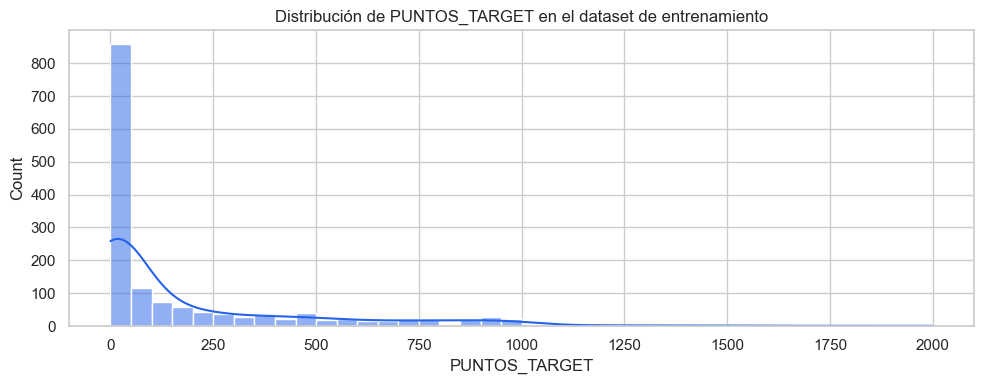

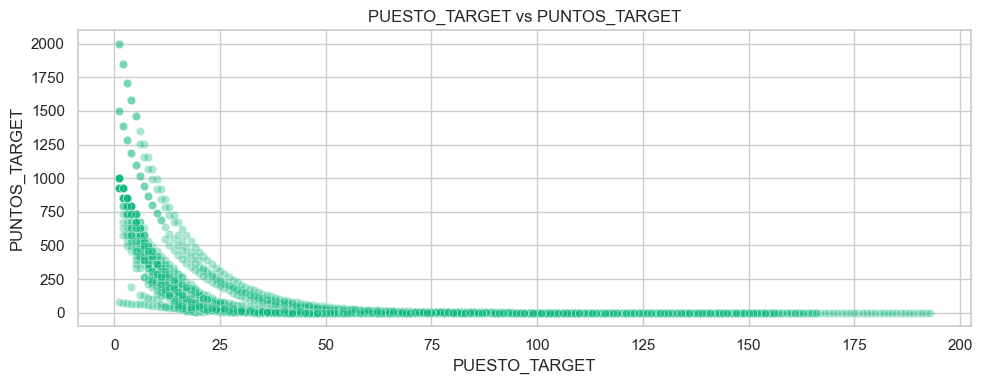

In [22]:
if DATA_AVAILABLE:
    if 'PUNTOS_TARGET' in df_train.columns:
        target_col = 'PUNTOS_TARGET'
    elif 'PUESTO_TARGET' in df_train.columns:
        target_col = 'PUESTO_TARGET'
    elif MODEL_TARGET_COL is not None and MODEL_TARGET_COL in df_train.columns:
        target_col = MODEL_TARGET_COL
    else:
        target_col = None

    print('Target elegido para el EDA del train:', target_col)
    if target_col is not None:
        display(df_train[target_col].describe())
        plt.figure(figsize=(10, 4))
        sns.histplot(df_train[target_col].dropna(), bins=40, kde=True, color='#2563eb')
        plt.title(f'Distribución de {target_col} en el dataset de entrenamiento')
        plt.tight_layout()
        plt.show()

        if 'PUNTOS_TARGET' in df_train.columns and 'PUESTO_TARGET' in df_train.columns:
            plt.figure(figsize=(10, 4))
            sns.scatterplot(data=df_train, x='PUESTO_TARGET', y='PUNTOS_TARGET', alpha=0.35, color='#10b981')
            plt.title('PUESTO_TARGET vs PUNTOS_TARGET')
            plt.tight_layout()
            plt.show()
    else:
        print('No se pudo identificar la columna objetivo del train.')
else:
    print('No hay datos disponibles para analizar el target del train.')


## 5. Outliers básicos

Usamos el criterio IQR para detectar valores extremos en columnas numéricas clave.

In [7]:
numeric_cols = df_resultados.select_dtypes(include=[np.number]).columns.tolist()
summary = []
for col in numeric_cols:
    series = df_resultados[col].dropna()
    if series.empty:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((series < lower) | (series > upper)).sum()
    summary.append({
        'columna': col,
        'outliers': int(outliers),
        'pct_outliers': round(outliers / len(series) * 100, 2),
        'min': float(series.min()),
        'max': float(series.max())
    })

if summary:
    df_outliers = pd.DataFrame(summary).sort_values('pct_outliers', ascending=False)
else:
    df_outliers = pd.DataFrame(columns=['columna', 'outliers', 'pct_outliers', 'min', 'max'])
    print('No hay datos suficientes para calcular outliers todavía.')

display(df_outliers)

,columna,outliers,pct_outliers,min,max
3,puntos,177,11.61,0.519694,2000.0
4,puesto,56,3.67,1.000000,193.0
0,season,0,0.00,2025.000000,2025.0
2,prueba_id,0,0.00,1264.000000,1411.0
1,ranking_type_id,0,0.00,6.000000,6.0


## 6. Atletas con poca participación

Uno de los puntos del sprint es detectar atletas con muy pocas carreras completadas para entender la cobertura del dataset.

In [8]:
athlete_col_candidates = [c for c in df_resultados.columns if 'deport' in c.lower() or 'atleta' in c.lower() or 'document' in c.lower()]
print('Posibles columnas de atleta:', athlete_col_candidates)

if athlete_col_candidates:
    athlete_col = athlete_col_candidates[0]
    participaciones = df_resultados.groupby(athlete_col).size().sort_values(ascending=True)
    display(participaciones.head(20).to_frame('carreras'))
    pct_30 = (participaciones < max(1, participaciones.max() * 0.3)).mean() * 100
    print(f'Atletas con menos del 30% de sus carreras respecto al máximo observado: {pct_30:.2f}%')
else:
    print('No se ha encontrado una columna de atleta evidente para calcular participación.')

Posibles columnas de atleta: ['deportista_documento']


,carreras
deportista_documento,
Z1657230Q,1
Z1588961B,1
Z0871025C,1
03917630V,1
03928807Q,1
03947006E,1
03950964R,1
03961342Y,1
04199887H,1


Atletas con menos del 30% de sus carreras respecto al máximo observado: 73.15%


## 7. Correlaciones básicas

Miramos relaciones lineales simples entre variables numéricas para detectar dependencias evidentes.

Columnas numéricas filtradas para correlación: ['puntos', 'puesto']


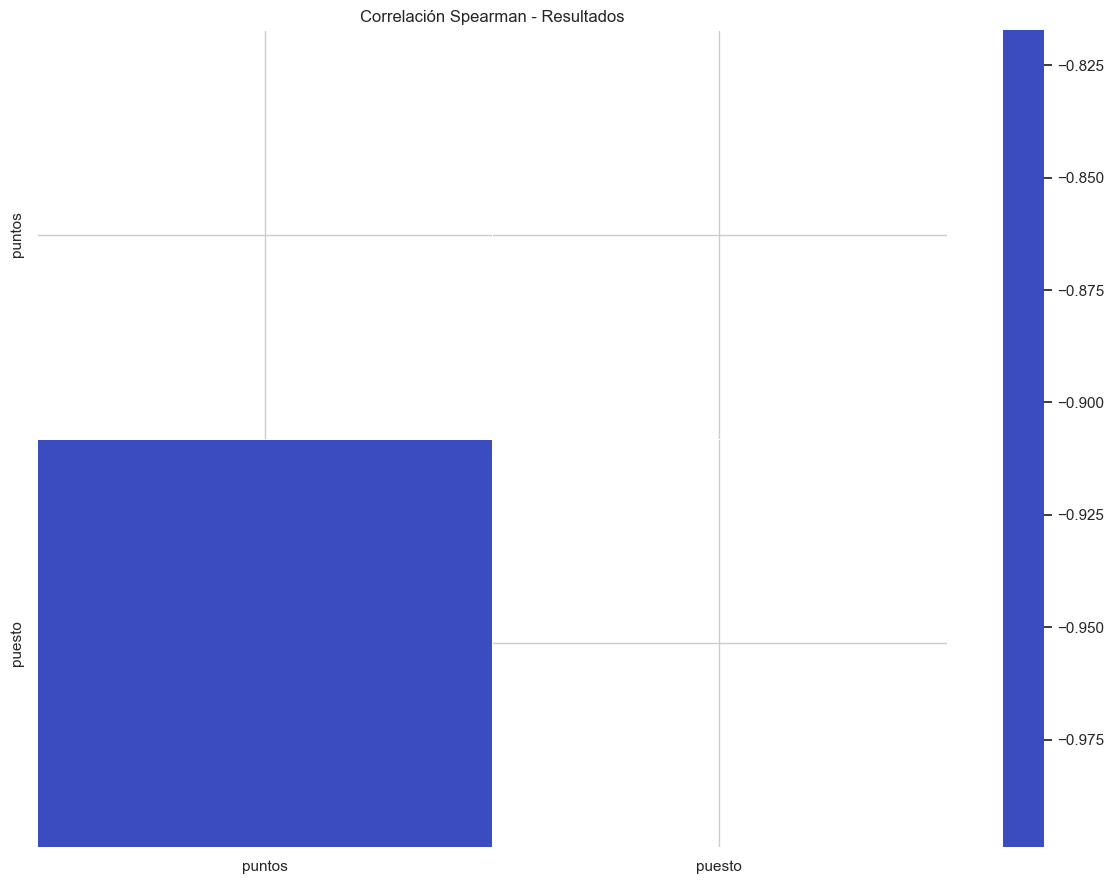

Pares con |spearman| >= 0.5 (ordenados):


puntos  puesto    0.908051
dtype: float64

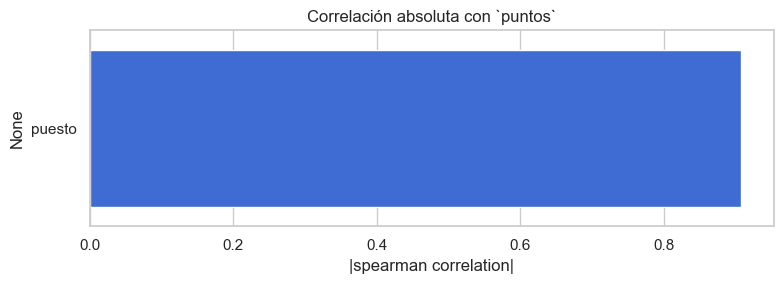

In [16]:
if DATA_AVAILABLE:
    corr_cols = relevant_numeric_columns(df_resultados)
    # eliminar columnas que parezcan identificadores o con muy baja variabilidad
    id_tokens = ['id', 'hash', 'codigo', 'code', 'registro']
    corr_cols = [c for c in corr_cols if not any(tok in c.lower() for tok in id_tokens)]

    # Si el filtrado dejó pocas columnas, usar una selección más amplia basada en dtype
    max_display = 30
    if len(corr_cols) < 2:
        numeric_all = [c for c in df_resultados.select_dtypes(include=[np.number]).columns]
        numeric_all = [c for c in numeric_all if not any(tok in c.lower() for tok in id_tokens)]
        numeric_all = [c for c in numeric_all if df_resultados[c].nunique(dropna=True) > 1]
        # priorizar 'puntos' y 'puesto' si existen
        pref = []
        if 'puntos' in numeric_all:
            pref.append('puntos')
            numeric_all.remove('puntos')
        if 'puesto' in numeric_all:
            pref.append('puesto')
            numeric_all.remove('puesto')
        corr_cols = pref + numeric_all[:max_display - len(pref)]

    # Priorizar la columna objetivo si existe y limitar el número de variables para visualizar
    if 'puntos' in df_resultados.columns and 'puntos' in corr_cols:
        base = [c for c in corr_cols if c != 'puntos']
        try:
            corr_with_target = df_resultados[base].corrwith(df_resultados['puntos'], method='spearman').abs().sort_values(ascending=False)
            top = corr_with_target.head(max(5, max_display - 1)).index.tolist()
            corr_cols = ['puntos'] + top
        except Exception:
            corr_cols = ['puntos'] + base[:max_display-1]
    elif 'puesto' in df_resultados.columns and 'puesto' in corr_cols and len(corr_cols) > 1:
        corr_cols = ['puesto'] + [c for c in corr_cols if c != 'puesto'][:max_display-1]
    else:
        corr_cols = corr_cols[:max_display]

    print('Columnas numéricas filtradas para correlación:', corr_cols)
    # Usamos clustermap y mostramos pares destacados con umbral 0.5
    plot_correlation_heatmap(df_resultados, corr_cols, 'Resultados', method='spearman', top_pairs_threshold=0.5)
else:
    print('No hay suficientes columnas numéricas para dibujar correlaciones.')


In [13]:
# Diagnóstico: comprobar corr_cols y ejecutar un plot de prueba
try:
    print('corr_cols (len):', len(corr_cols))
    print('corr_cols sample:', corr_cols[:30])
except NameError:
    print('corr_cols no definida')

# intentar una ejecución corta del plot en try/except
try:
    test_cols = corr_cols[:12] if 'corr_cols' in globals() else []
    if len(test_cols) >= 2:
        plot_correlation_heatmap(df_resultados, test_cols, 'Resultados - Test', method='spearman', top_pairs_threshold=0.5)
    else:
        print('No hay suficientes columnas para plot de prueba:', test_cols)
except Exception as e:
    import traceback
    traceback.print_exc()
    print('Error al dibujar plot:', e)


corr_cols (len): 1
corr_cols sample: ['puntos']
No hay suficientes columnas para plot de prueba: ['puntos']


## 8. Comprobación de DSQ / DNF / DNS

Buscamos si el dataset trae alguna columna o valor que permita construir la variable `descalificado`.

In [23]:
explicit_status_cols = [c for c in df_resultados.columns if c.lower() in {'dsq', 'dnf', 'dns', 'descalificado', 'status', 'estado', 'resultado'}]
print('Columnas explícitas de estado encontradas en df_resultados:', explicit_status_cols)

if explicit_status_cols:
    for col in explicit_status_cols:
        display(df_resultados[col].astype(str).value_counts(dropna=False).head(20))
else:
    print('En el esquema procesado actual no aparece una columna explícita de DSQ/DNF/DNS.')
    print('Conclusión útil: la variable descalificado no se puede construir de forma fiable desde df_resultados sin consultar el dato bruto o el diccionario de datos.')


Columnas explícitas de estado encontradas en df_resultados: []
En el esquema procesado actual no aparece una columna explícita de DSQ/DNF/DNS.
Conclusión útil: la variable descalificado no se puede construir de forma fiable desde df_resultados sin consultar el dato bruto o el diccionario de datos.


## 9. EDA visual ampliado

A continuación ampliamos el análisis con tablas resumen, distribución de variables, categorías, relaciones bivariantes y un vistazo a los atípicos y desequilibrios del dataset.

In [11]:
if DATA_AVAILABLE:
    print('## Resumen global')
    print('Dimensiones:')
    print('  Deportistas:', df_deportistas.shape)
    print('  Pruebas:', df_pruebas.shape)
    print('  Clubes:', df_clubes.shape)
    print('  Resultados:', df_resultados.shape)
    print()
    print('Memoria aproximada por dataframe (MB):')
    for name, df in [('Deportistas', df_deportistas), ('Pruebas', df_pruebas), ('Clubes', df_clubes), ('Resultados', df_resultados)]:
        print(f'  {name}: {df.memory_usage(deep=True).sum() / 1024**2:.2f}')
    print()
    print('Resumen de nulos por tabla:')
    for name, df in [('Deportistas', df_deportistas), ('Pruebas', df_pruebas), ('Clubes', df_clubes), ('Resultados', df_resultados)]:
        missing_pct = df.isna().mean().mul(100).round(2)
        top_missing = missing_pct[missing_pct > 0].sort_values(ascending=False).head(10)
        print(f'--- {name} ---')
        if top_missing.empty:
            print('  Sin nulos')
        else:
            print(top_missing.to_string())
            print()
    plot_missingness(df_deportistas, 'Deportistas')
    plot_missingness(df_pruebas, 'Pruebas')
    plot_missingness(df_clubes, 'Clubes')
    plot_missingness(df_resultados, 'Resultados')
else:
    print('No hay datos cargados para el resumen global.')

## Resumen global
Dimensiones:
  Deportistas: (1028, 4)
  Pruebas: (128, 14)
  Clubes: (476, 5)
  Resultados: (1525, 6)

Memoria aproximada por dataframe (MB):
  Deportistas: 0.30
  Pruebas: 0.05
  Clubes: 0.11
  Resultados: 0.15

Resumen de nulos por tabla:
--- Deportistas ---
  Sin nulos
--- Pruebas ---
  Sin nulos
--- Clubes ---
  Sin nulos
--- Resultados ---
  Sin nulos
Sin nulos en Deportistas
Sin nulos en Pruebas
Sin nulos en Clubes
Sin nulos en Resultados


## Variables numéricas interpretables
--- Deportistas ---
No hay columnas numéricas útiles
Sin columnas numéricas útiles para Deportistas
--- Pruebas ---
['championship_level', 'lat', 'lng', 'altitud', 'temperatura_max', 'humedad_media', 'precipitacion', 'viento_max']


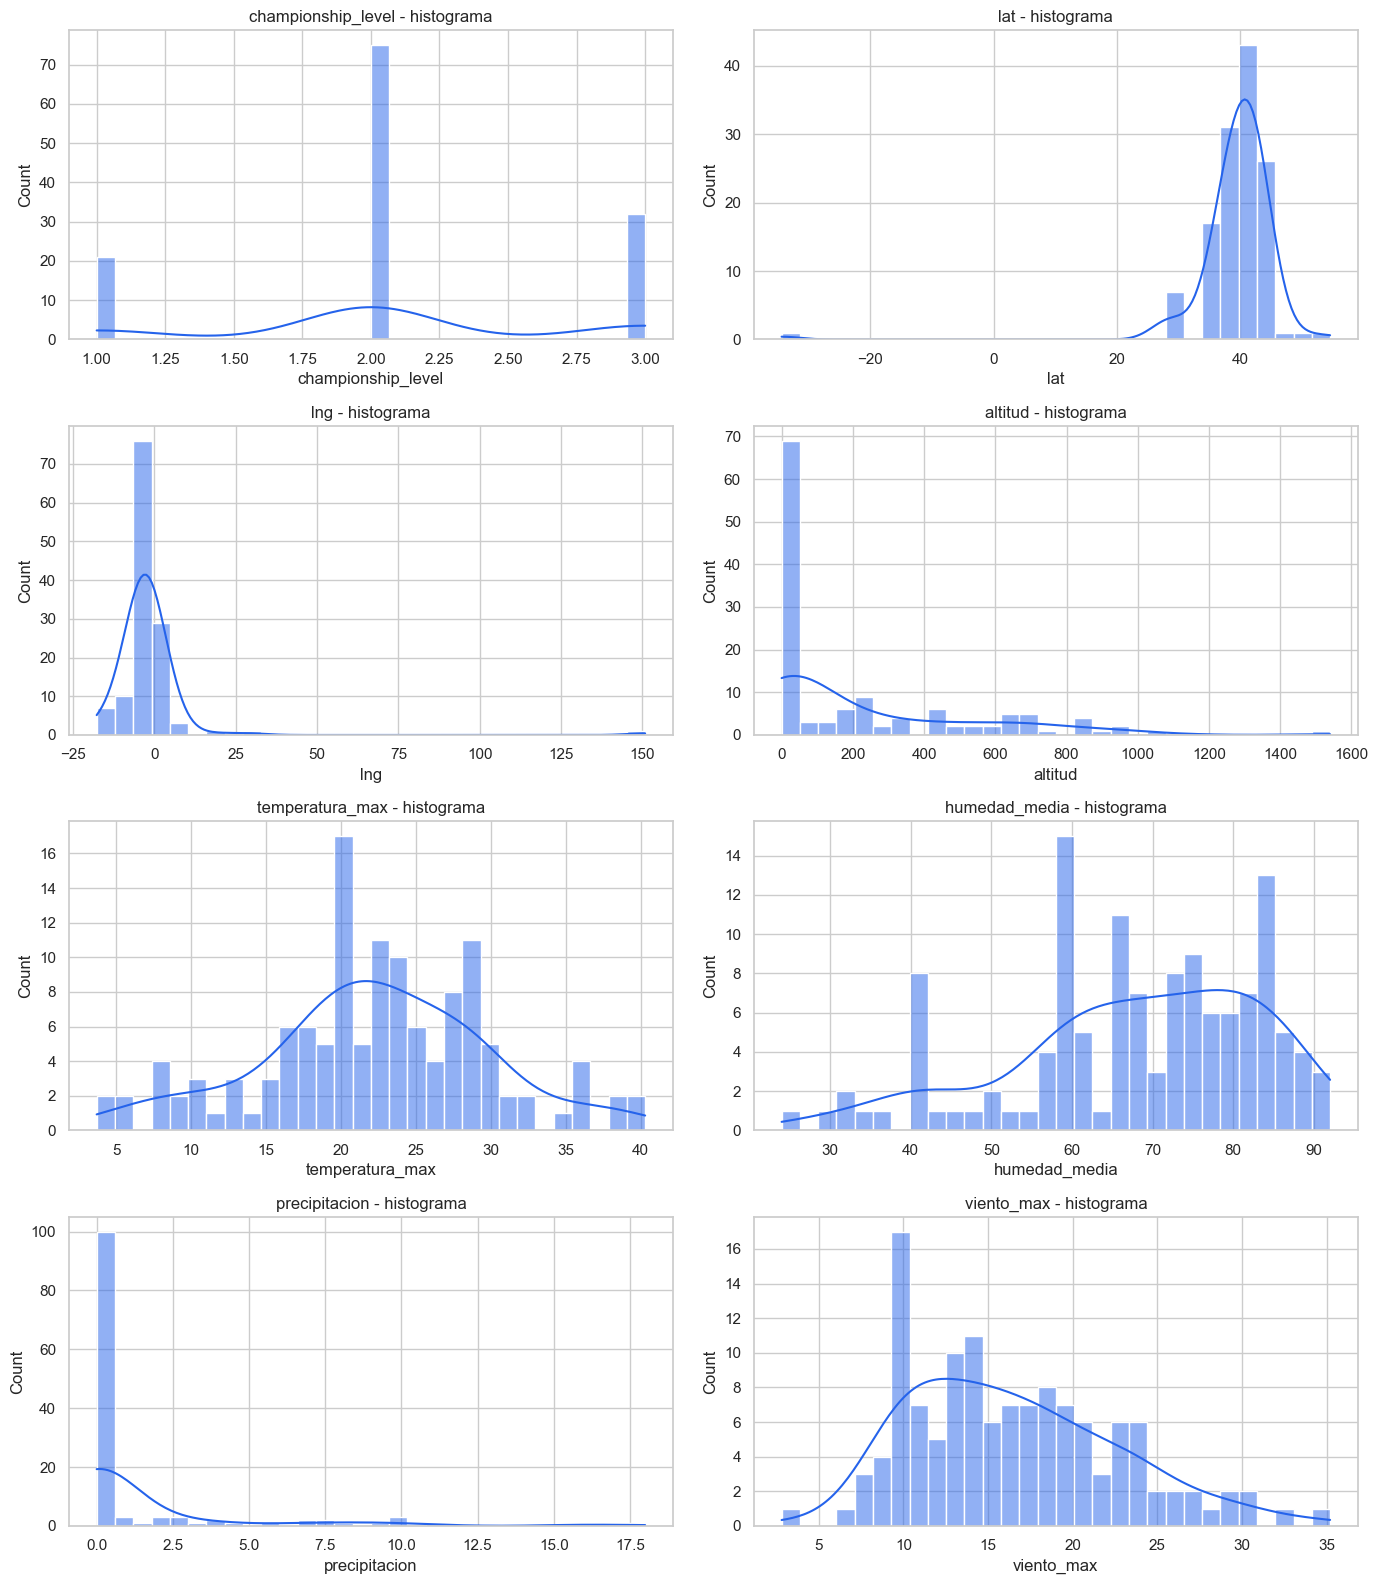

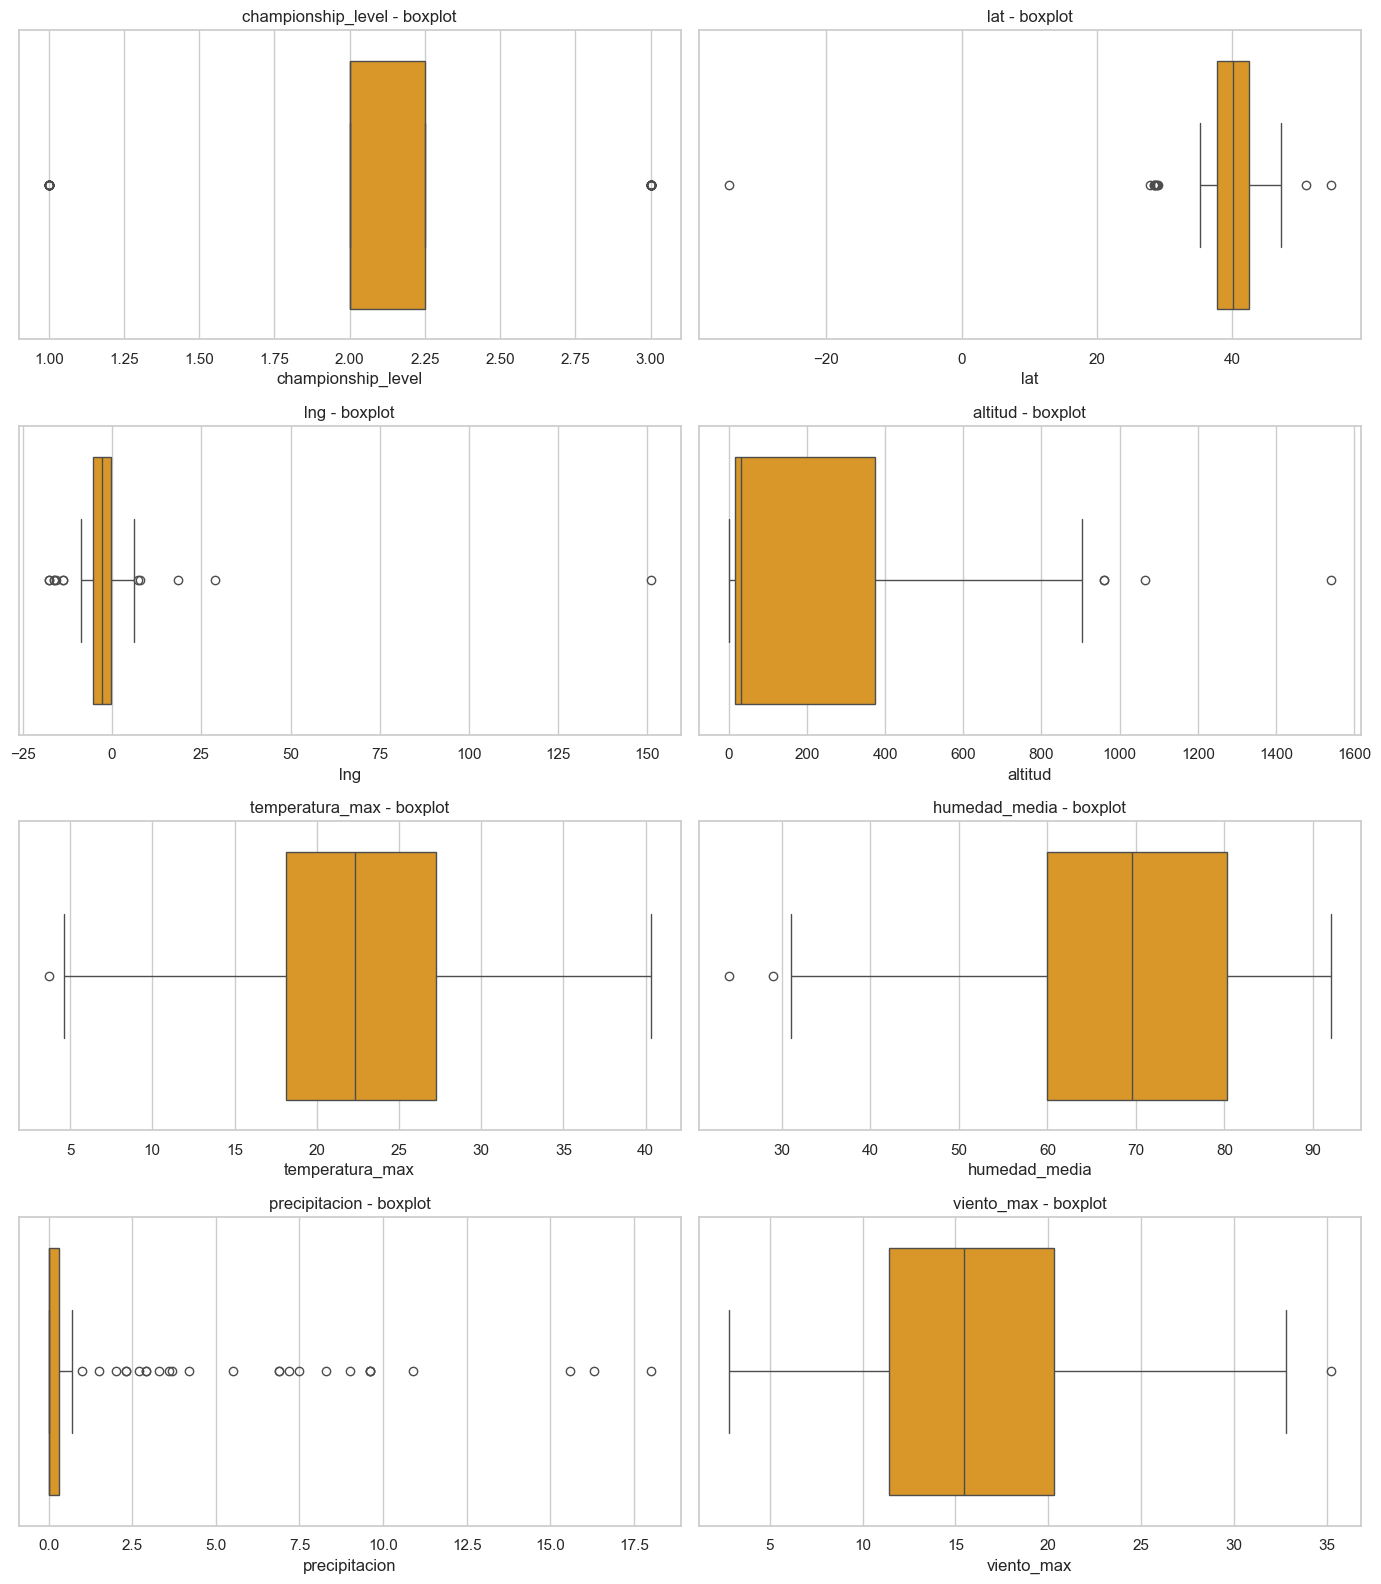

--- Clubes ---
['lat', 'lng']


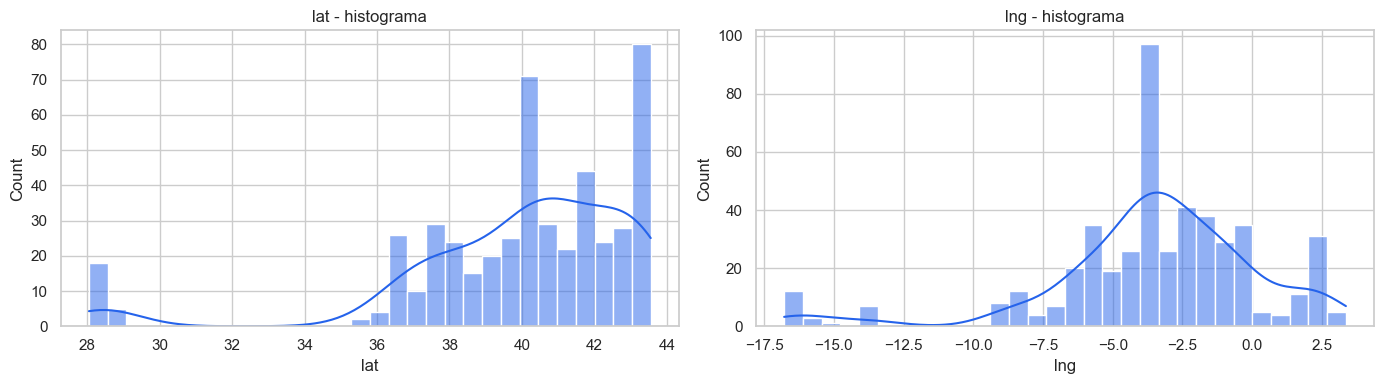

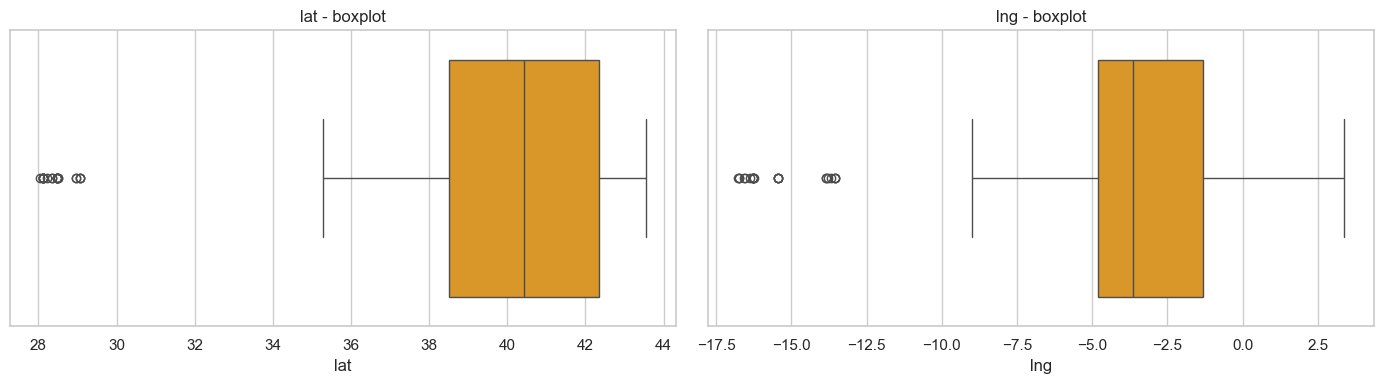

--- Resultados ---
['puntos']


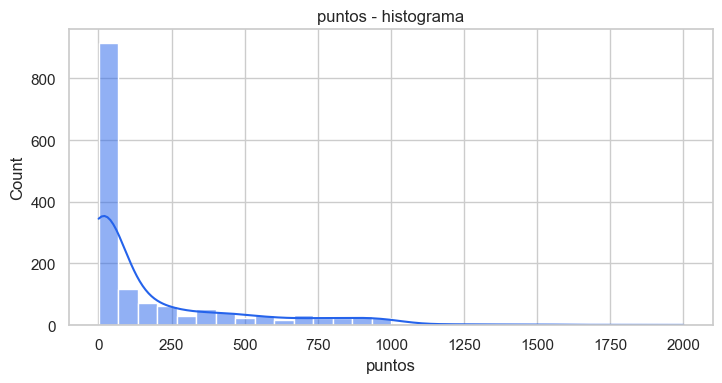

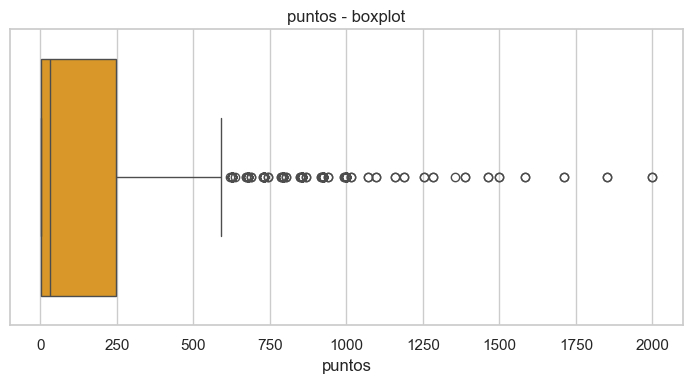

## Variables categóricas / discretas
--- Deportistas ---
['DOCUMENTO', 'NOMBRE', 'CLUB', 'GGEE']


C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Te

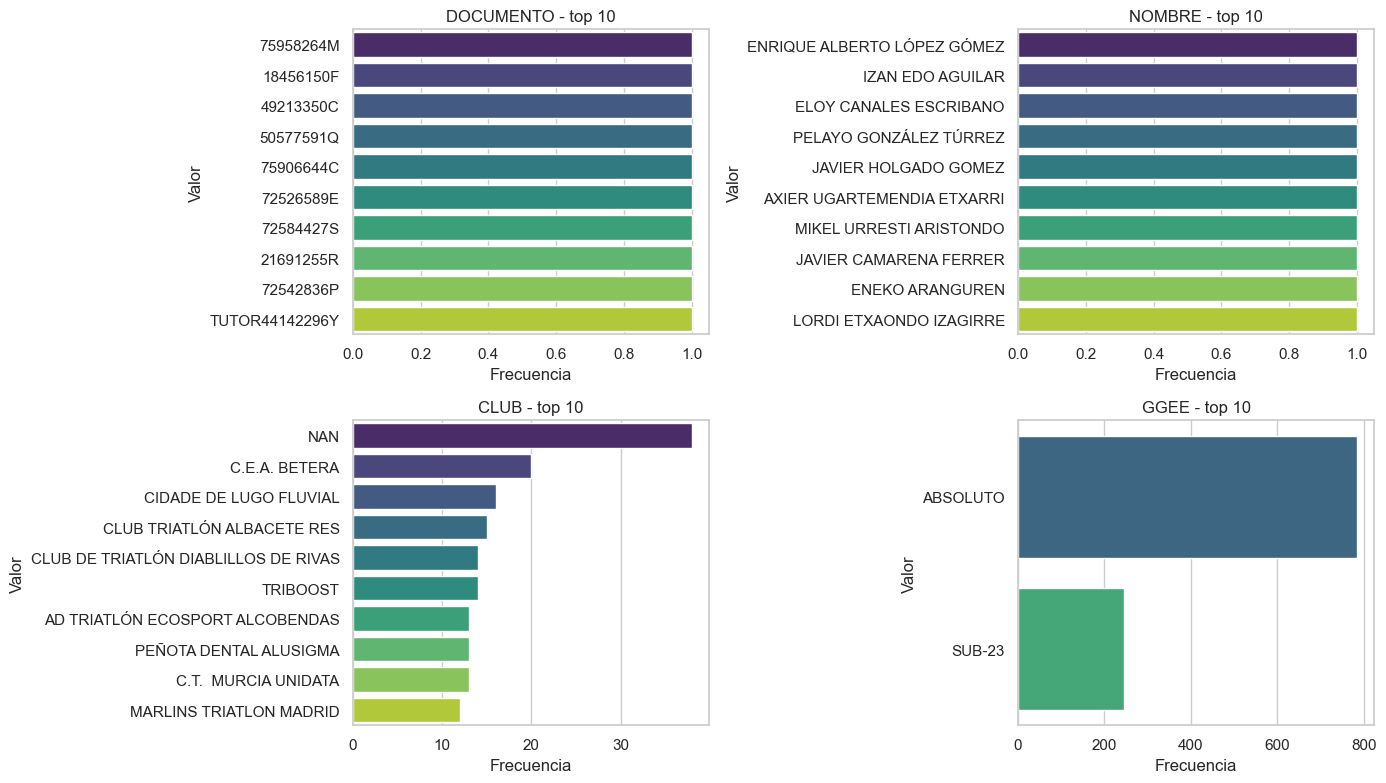

--- Pruebas ---
['nombre', 'fecha', 'ciudad', 'provincia']


C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Te

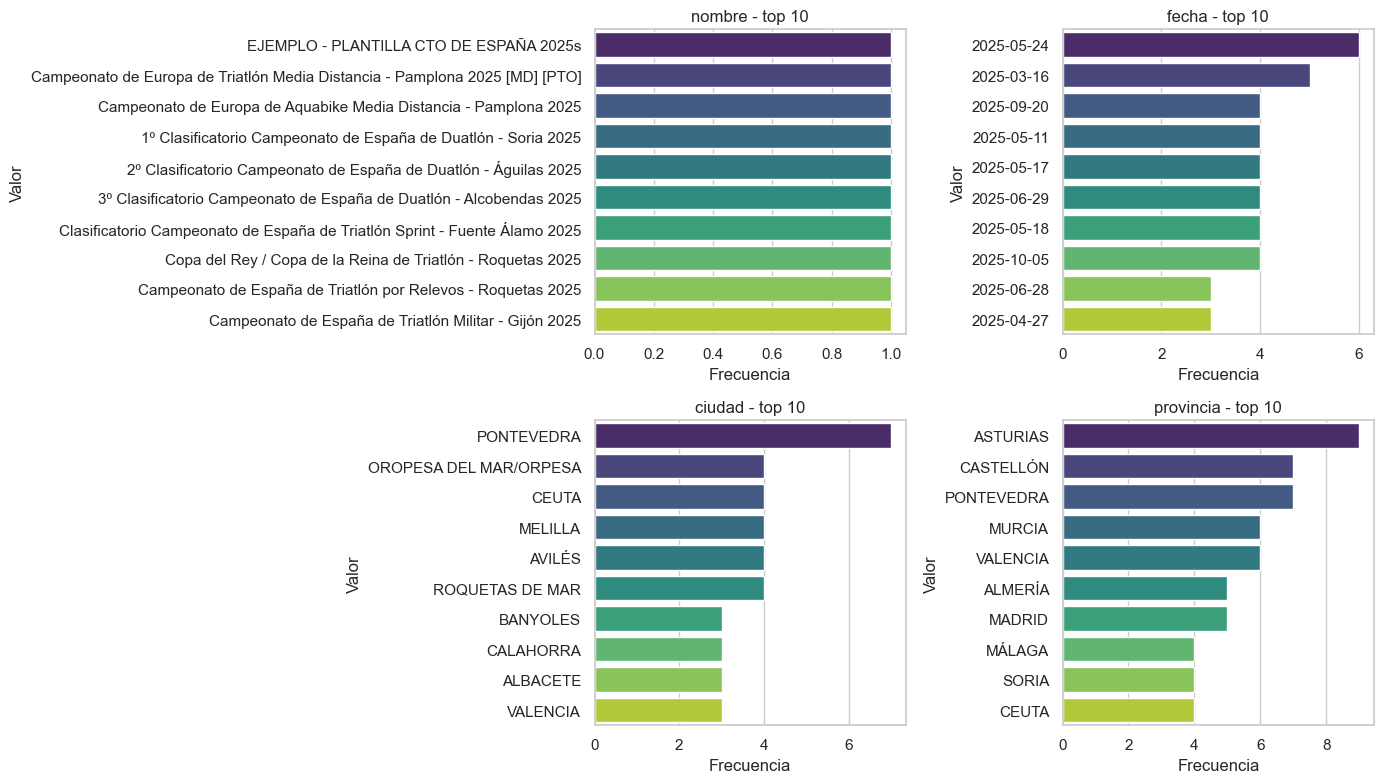

--- Clubes ---
['club', 'ciudad_sede', 'provincia']


C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')


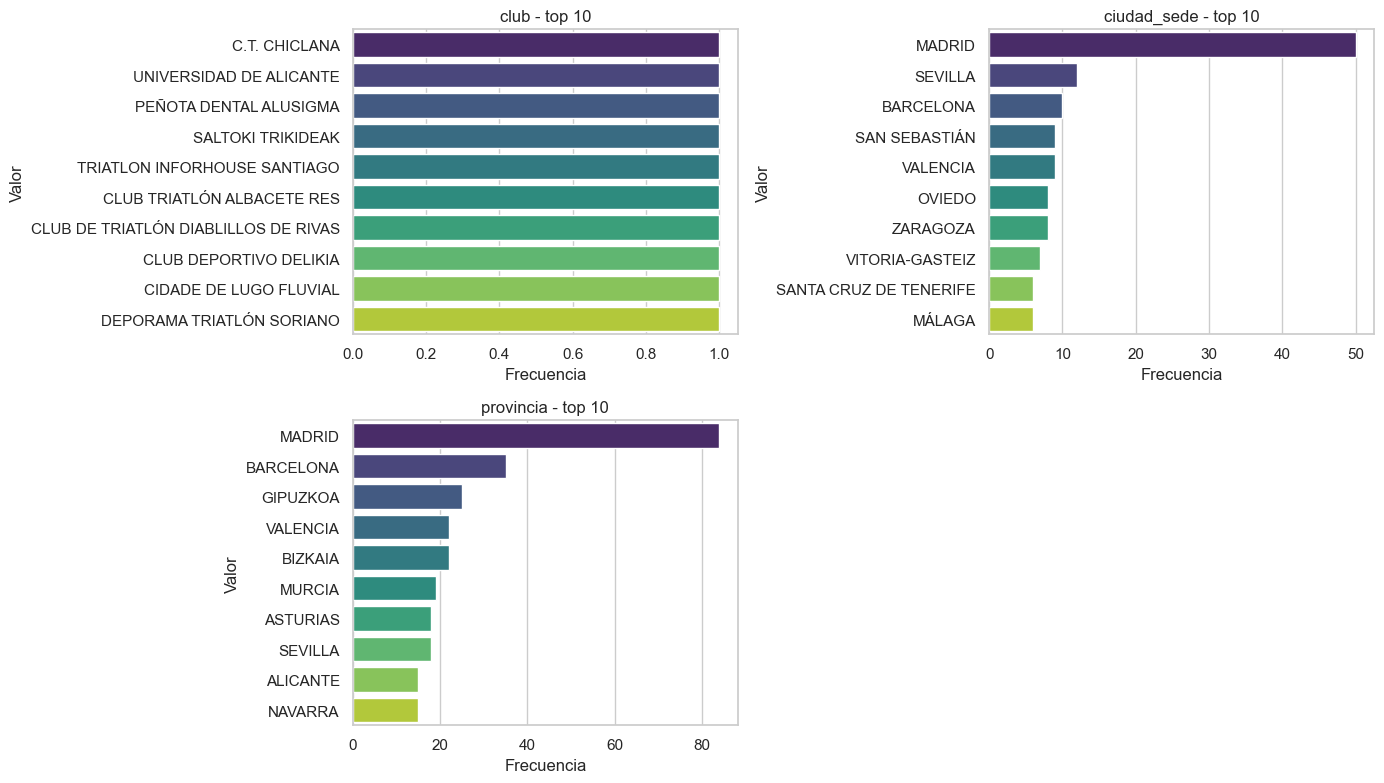

--- Resultados ---
['deportista_documento']


C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')


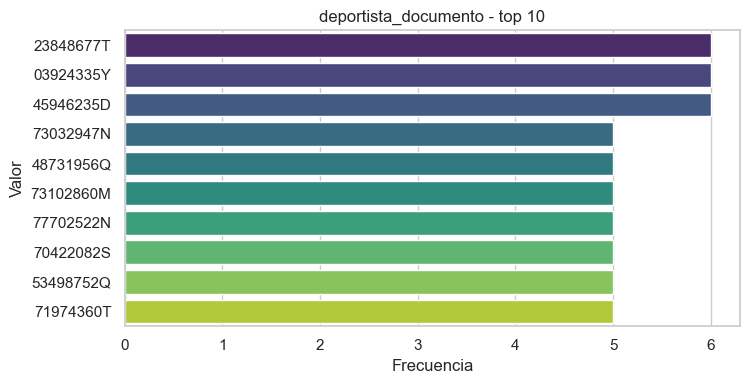

## Bivariantes clave


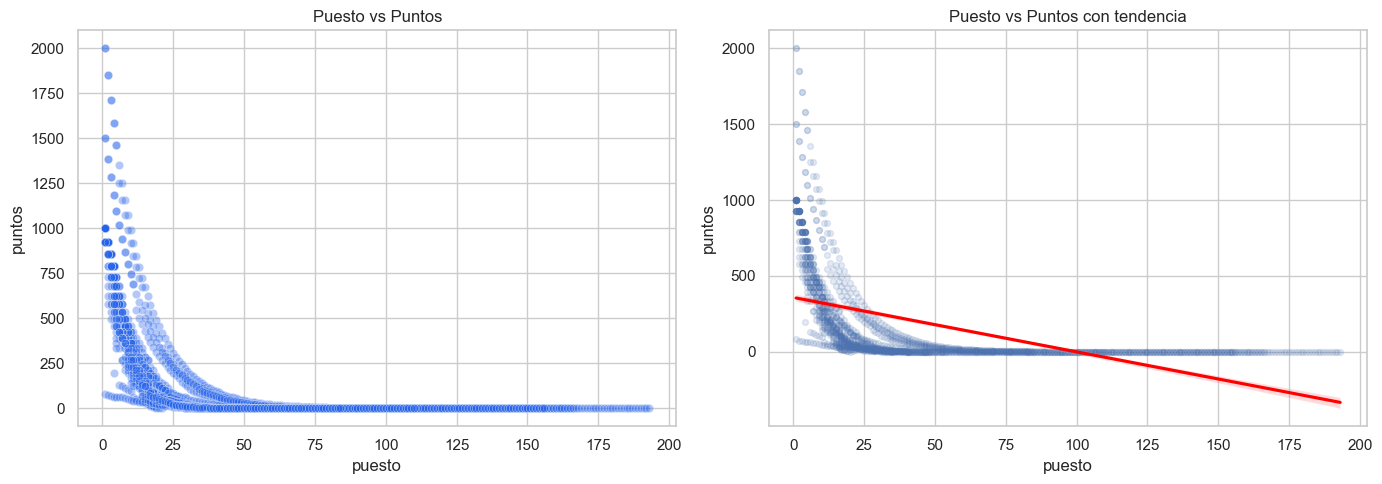

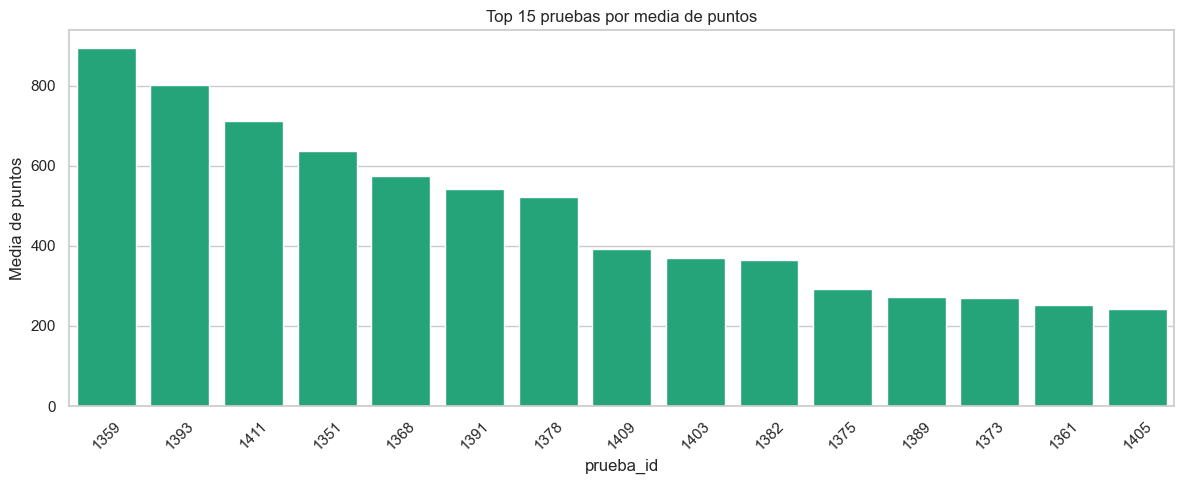

C:\Users\mario\AppData\Local\Temp\ipykernel_3928\4248987129.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_resultados, x='ranking_type_id', y='puntos', palette='Set2')


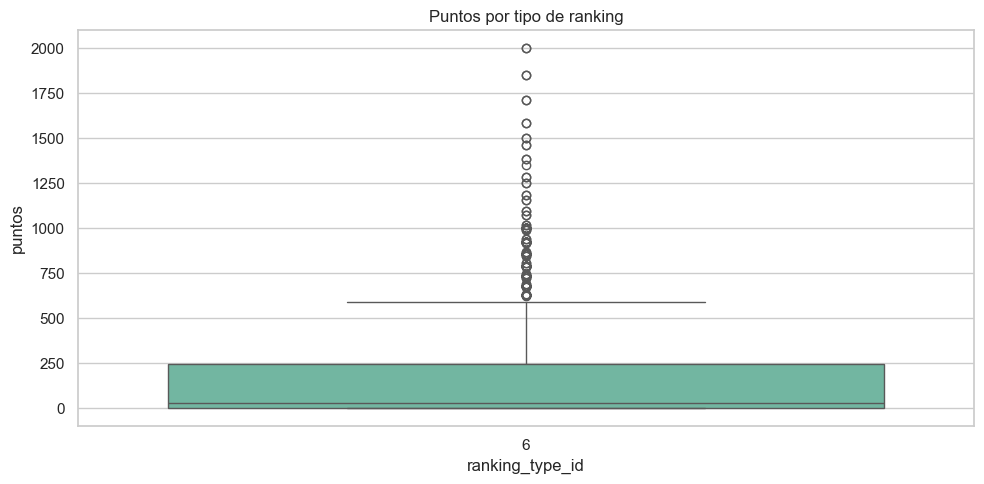

In [12]:
if DATA_AVAILABLE:
    print('## Variables numéricas interpretables')
    for name, df in [('Deportistas', df_deportistas), ('Pruebas', df_pruebas), ('Clubes', df_clubes), ('Resultados', df_resultados)]:
        cols = relevant_numeric_columns(df)
        print(f'--- {name} ---')
        print(cols if cols else 'No hay columnas numéricas útiles')
        plot_numeric_overview(df, cols, name, max_cols=10)
else:
    print('No hay datos cargados para el análisis numérico.')

if DATA_AVAILABLE:
    print('## Variables categóricas / discretas')
    for name, df in [('Deportistas', df_deportistas), ('Pruebas', df_pruebas), ('Clubes', df_clubes), ('Resultados', df_resultados)]:
        cols = categorical_columns(df, max_unique=12)
        cols = [c for c in cols if c not in relevant_numeric_columns(df)]
        print(f'--- {name} ---')
        print(cols if cols else 'No hay columnas categóricas útiles')
        plot_categorical_overview(df, cols, name, max_cols=8, top_n=10)
else:
    print('No hay datos cargados para el análisis categórico.')

if DATA_AVAILABLE:
    print('## Bivariantes clave')
    if 'puesto' in df_resultados.columns and 'puntos' in df_resultados.columns:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.scatterplot(data=df_resultados, x='puesto', y='puntos', alpha=0.35, ax=axes[0], color='#2563eb')
        axes[0].set_title('Puesto vs Puntos')
        sns.regplot(data=df_resultados, x='puesto', y='puntos', scatter_kws={'alpha': 0.15, 's': 18}, line_kws={'color': 'red'}, ax=axes[1])
        axes[1].set_title('Puesto vs Puntos con tendencia')
        plt.tight_layout()
        plt.show()
    if 'prueba_id' in df_resultados.columns and 'puntos' in df_resultados.columns:
        top_pruebas = df_resultados.groupby('prueba_id')['puntos'].mean().sort_values(ascending=False).head(15)
        plt.figure(figsize=(12, 5))
        sns.barplot(x=top_pruebas.index.astype(str), y=top_pruebas.values, color='#10b981')
        plt.title('Top 15 pruebas por media de puntos')
        plt.xlabel('prueba_id')
        plt.ylabel('Media de puntos')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    if 'ranking_type_id' in df_resultados.columns and 'puntos' in df_resultados.columns:
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=df_resultados, x='ranking_type_id', y='puntos', palette='Set2')
        plt.title('Puntos por tipo de ranking')
        plt.tight_layout()
        plt.show()
else:
    print('No hay datos cargados para los bivariantes.')

## 10. EDA del dataset de entrenamiento

Ahora cambiamos el foco al dataset que realmente se usará para entrenar el modelo. Aquí buscamos entender su estructura final, posibles fugas de información, calidad de las variables y relaciones relevantes para el modelado.

Ruta dataset entrenamiento: c:\Users\mario\PycharmProjects\conersys_predictivo_triatlon_elitemasculino\data\processed\trm_2025_azure_automl.csv
Shape train: (1525, 27)


,ATLETA_ID_HASH,CLUB,GGEE,PRUEBA_ID,CHAMPIONSHIP_LEVEL,ALTITUD,TEMPERATURA_MAX,HUMEDAD_MEDIA,PRECIPITACION,VIENTO_MAX,IS_EXTREME_HEAT,IS_WET_RACE,VIAJE_DISTANCIA_KM,ES_LOCAL,MES_CARRERA,MES_SIN,MES_COS,DAYS_SINCE_LAST_RACE,FATIGUE_INDEX,CLUB_POWER_SCORE,RECENT_AVG_PUNTOS,HIST_AVG_PUNTOS,HIST_STD_PUNTOS,HIST_MAX_PUNTOS,HIST_COUNT_PRUEBAS,PUESTO_TARGET,PUNTOS_TARGET
0,f96c7e5b0d3413e7,C.D.E. JEREZANA DE TRIATLÓN,ABSOLUTO,1380,3,18.0,28.2,46.0,0.0,20.9,0,0,79.293327,1,5,0.500000,-8.660254e-01,365,0.000000,24.420190,0.000000,0.000000,0.000000,0.000000,0,61,0.519694
1,e27fbe96459eda56,GALDAKAOKO MOZOILO TRIATHLON KLUB,ABSOLUTO,1358,2,845.0,5.3,88.0,6.9,11.4,0,1,107.808469,0,2,0.866025,5.000000e-01,365,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,29,60.409102
2,cf6d1b52c785ae66,TRI INFINITY MÓSTOLES,ABSOLUTO,1292,2,13.0,21.1,80.0,0.2,16.8,0,1,505.247974,0,5,0.500000,-8.660254e-01,14,0.066667,132.259757,52.437103,52.437103,51.821103,104.258206,2,94,1.313267
3,d3d72275ee25b06f,AD TRIATLÓN ECOSPORT ALCOBENDAS,ABSOLUTO,1298,2,18.0,30.2,61.0,0.0,10.5,1,0,391.966449,0,9,-1.000000,-1.836970e-16,119,0.000000,127.176426,12.703899,12.703899,0.000000,12.703899,1,137,0.600897
4,77bc1b30f34e18a3,CLUB TRIATLÓ VINARÒS,SUB-23,1291,2,4.0,22.1,55.0,0.0,14.9,0,0,50.329603,1,5,0.500000,-8.660254e-01,365,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,4,791.453125


--- Tipos de columnas ---


,ATLETA_ID_HASH,CLUB,GGEE,PRUEBA_ID,CHAMPIONSHIP_LEVEL,ALTITUD,TEMPERATURA_MAX,HUMEDAD_MEDIA,PRECIPITACION,VIENTO_MAX,IS_EXTREME_HEAT,IS_WET_RACE,VIAJE_DISTANCIA_KM,ES_LOCAL,MES_CARRERA,MES_SIN,MES_COS,DAYS_SINCE_LAST_RACE,FATIGUE_INDEX,CLUB_POWER_SCORE,RECENT_AVG_PUNTOS,HIST_AVG_PUNTOS,HIST_STD_PUNTOS,HIST_MAX_PUNTOS,HIST_COUNT_PRUEBAS,PUESTO_TARGET,PUNTOS_TARGET
dtype,object,object,object,int64,int64,float64,float64,float64,float64,float64,int64,int64,float64,int64,int64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64,int64,float64


--- Resumen de nulos ---


,nulos,pct_nulos,tipo
ATLETA_ID_HASH,0,0.0,object
CLUB,0,0.0,object
GGEE,0,0.0,object
PRUEBA_ID,0,0.0,int64
CHAMPIONSHIP_LEVEL,0,0.0,int64
ALTITUD,0,0.0,float64
TEMPERATURA_MAX,0,0.0,float64
HUMEDAD_MEDIA,0,0.0,float64
PRECIPITACION,0,0.0,float64
VIENTO_MAX,0,0.0,float64


--- Duplicados ---
Filas duplicadas: 0
Columnas numéricas útiles para train: ['CHAMPIONSHIP_LEVEL', 'ALTITUD', 'TEMPERATURA_MAX', 'HUMEDAD_MEDIA', 'PRECIPITACION', 'VIENTO_MAX', 'VIAJE_DISTANCIA_KM', 'MES_CARRERA', 'MES_SIN', 'MES_COS', 'DAYS_SINCE_LAST_RACE', 'FATIGUE_INDEX', 'CLUB_POWER_SCORE', 'RECENT_AVG_PUNTOS', 'HIST_AVG_PUNTOS', 'HIST_STD_PUNTOS', 'HIST_MAX_PUNTOS', 'HIST_COUNT_PRUEBAS', 'PUESTO_TARGET', 'PUNTOS_TARGET']
Columnas para correlación del train: ['CHAMPIONSHIP_LEVEL', 'ALTITUD', 'TEMPERATURA_MAX', 'HUMEDAD_MEDIA', 'PRECIPITACION', 'VIENTO_MAX', 'VIAJE_DISTANCIA_KM', 'MES_CARRERA', 'MES_SIN', 'MES_COS', 'DAYS_SINCE_LAST_RACE', 'FATIGUE_INDEX', 'CLUB_POWER_SCORE', 'RECENT_AVG_PUNTOS', 'HIST_AVG_PUNTOS', 'HIST_STD_PUNTOS', 'HIST_MAX_PUNTOS', 'HIST_COUNT_PRUEBAS', 'PUESTO_TARGET', 'PUNTOS_TARGET']


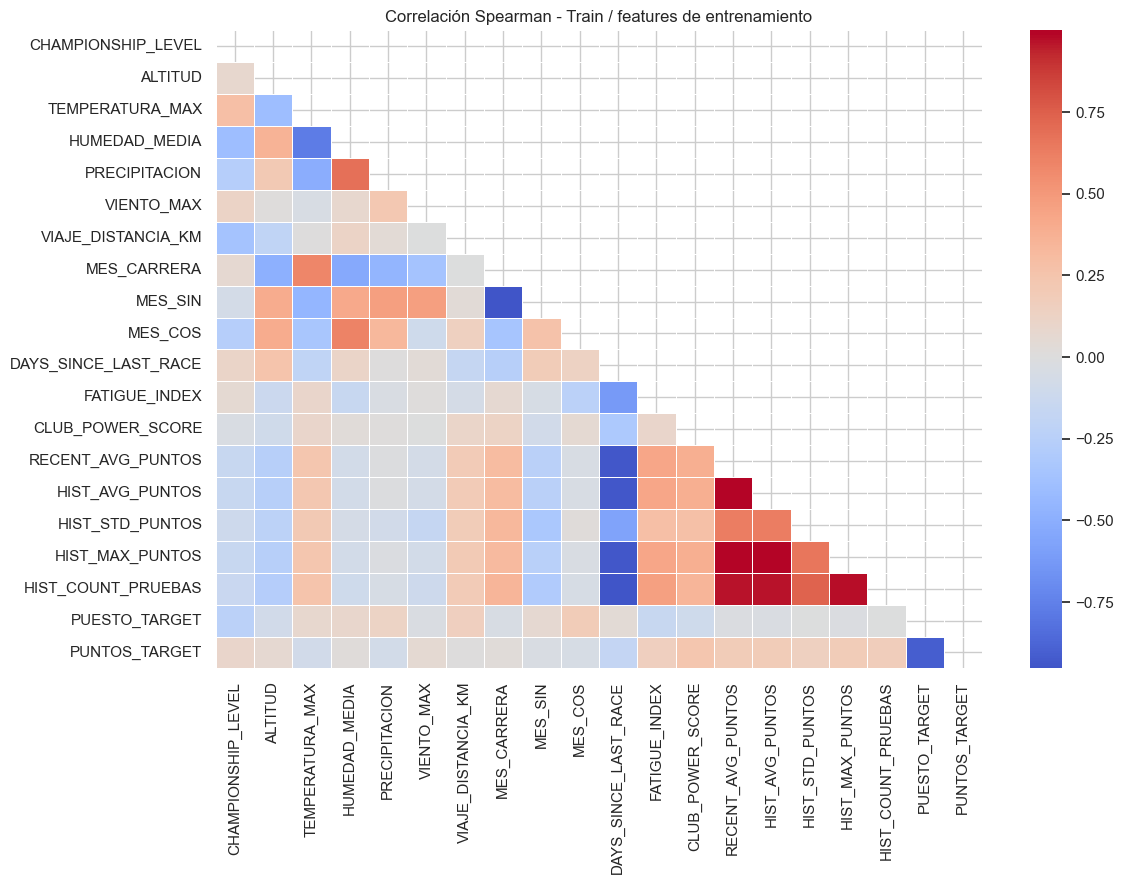

Pares con |spearman| >= 0.5 (ordenados):


RECENT_AVG_PUNTOS     HIST_AVG_PUNTOS       0.999804
HIST_AVG_PUNTOS       HIST_MAX_PUNTOS       0.998662
RECENT_AVG_PUNTOS     HIST_MAX_PUNTOS       0.998466
HIST_MAX_PUNTOS       HIST_COUNT_PRUEBAS    0.975507
RECENT_AVG_PUNTOS     HIST_COUNT_PRUEBAS    0.968113
HIST_AVG_PUNTOS       HIST_COUNT_PRUEBAS    0.968042
DAYS_SINCE_LAST_RACE  HIST_COUNT_PRUEBAS    0.952942
MES_CARRERA           MES_SIN               0.952532
DAYS_SINCE_LAST_RACE  HIST_MAX_PUNTOS       0.942557
                      HIST_AVG_PUNTOS       0.942293
                      RECENT_AVG_PUNTOS     0.942091
PUESTO_TARGET         PUNTOS_TARGET         0.908051
TEMPERATURA_MAX       HUMEDAD_MEDIA         0.769998
HIST_STD_PUNTOS       HIST_COUNT_PRUEBAS    0.734635
HUMEDAD_MEDIA         PRECIPITACION         0.683239
HIST_STD_PUNTOS       HIST_MAX_PUNTOS       0.660921
HIST_AVG_PUNTOS       HIST_STD_PUNTOS       0.633484
RECENT_AVG_PUNTOS     HIST_STD_PUNTOS       0.633425
DAYS_SINCE_LAST_RACE  FATIGUE_INDEX         0.

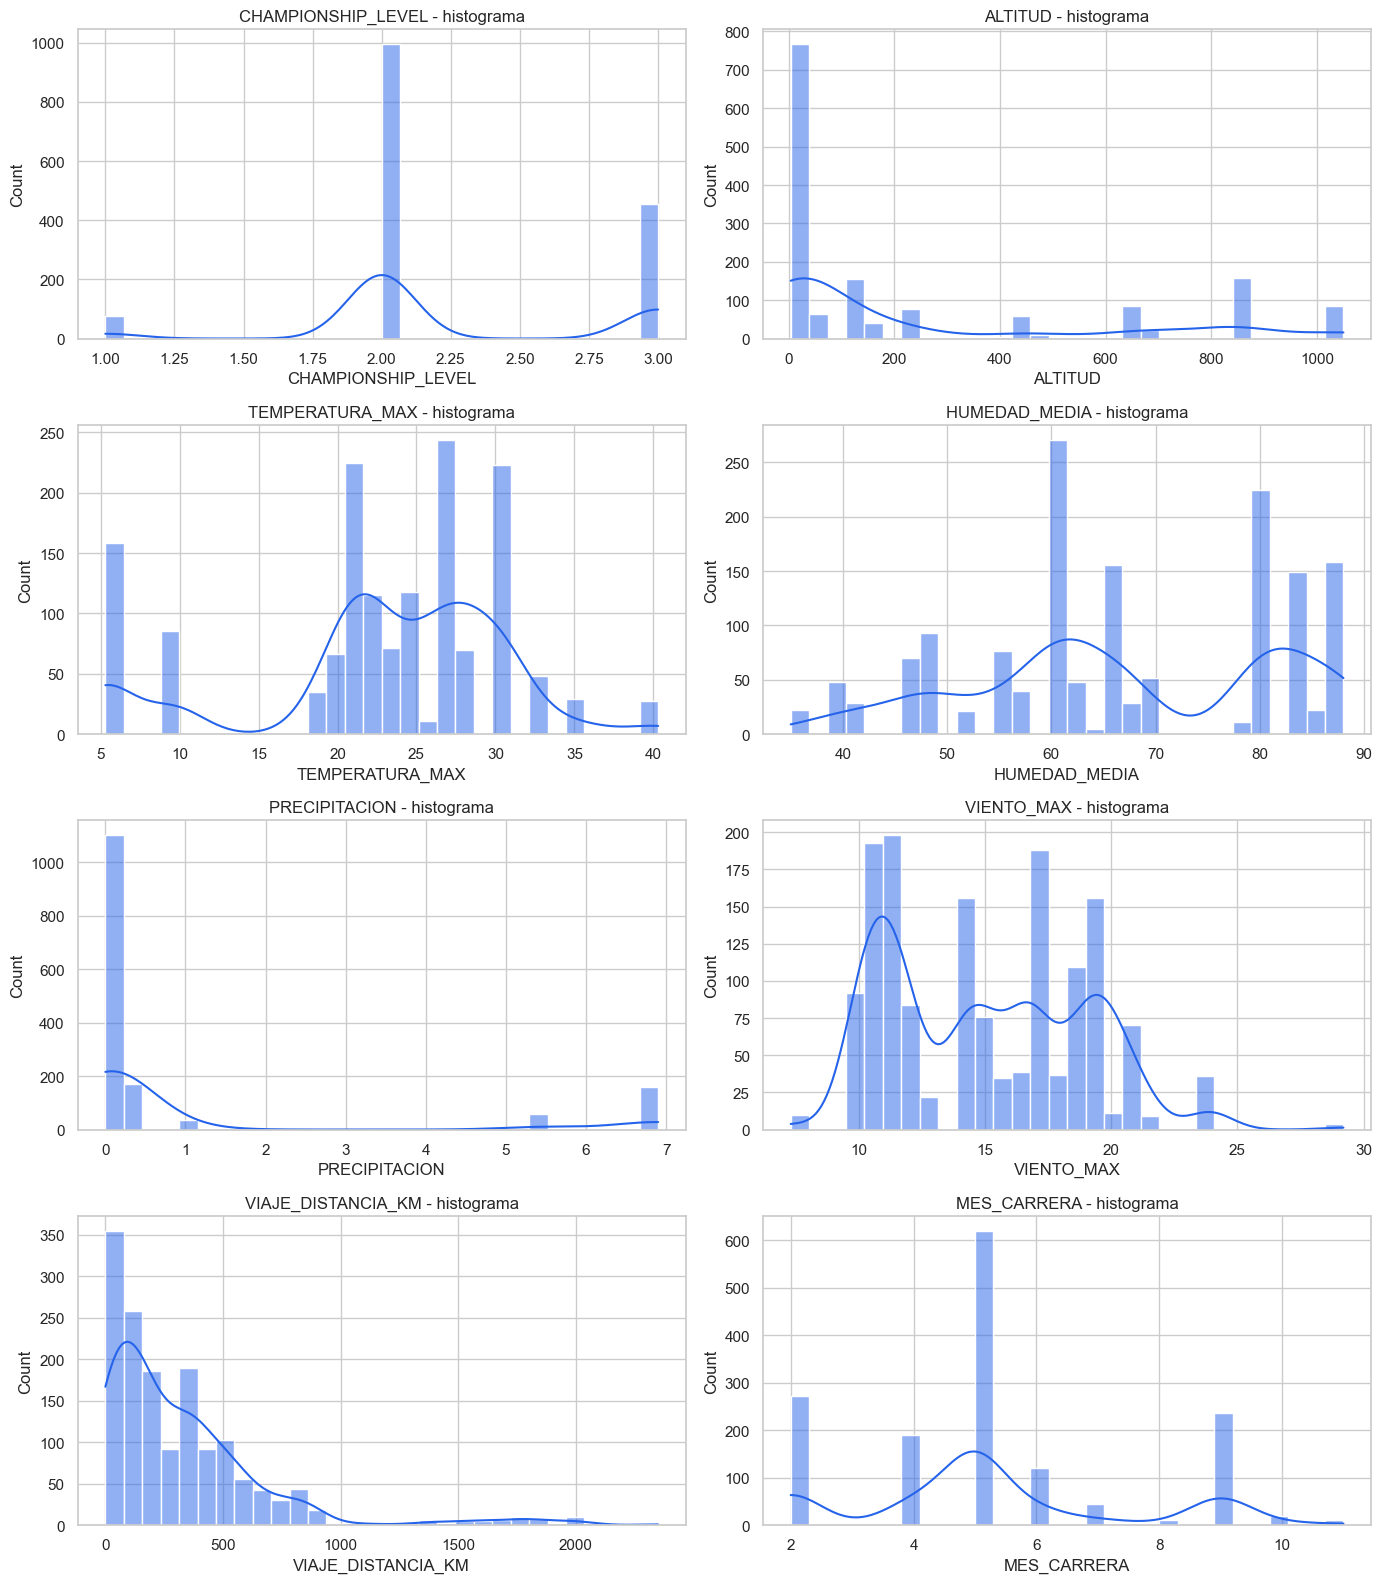

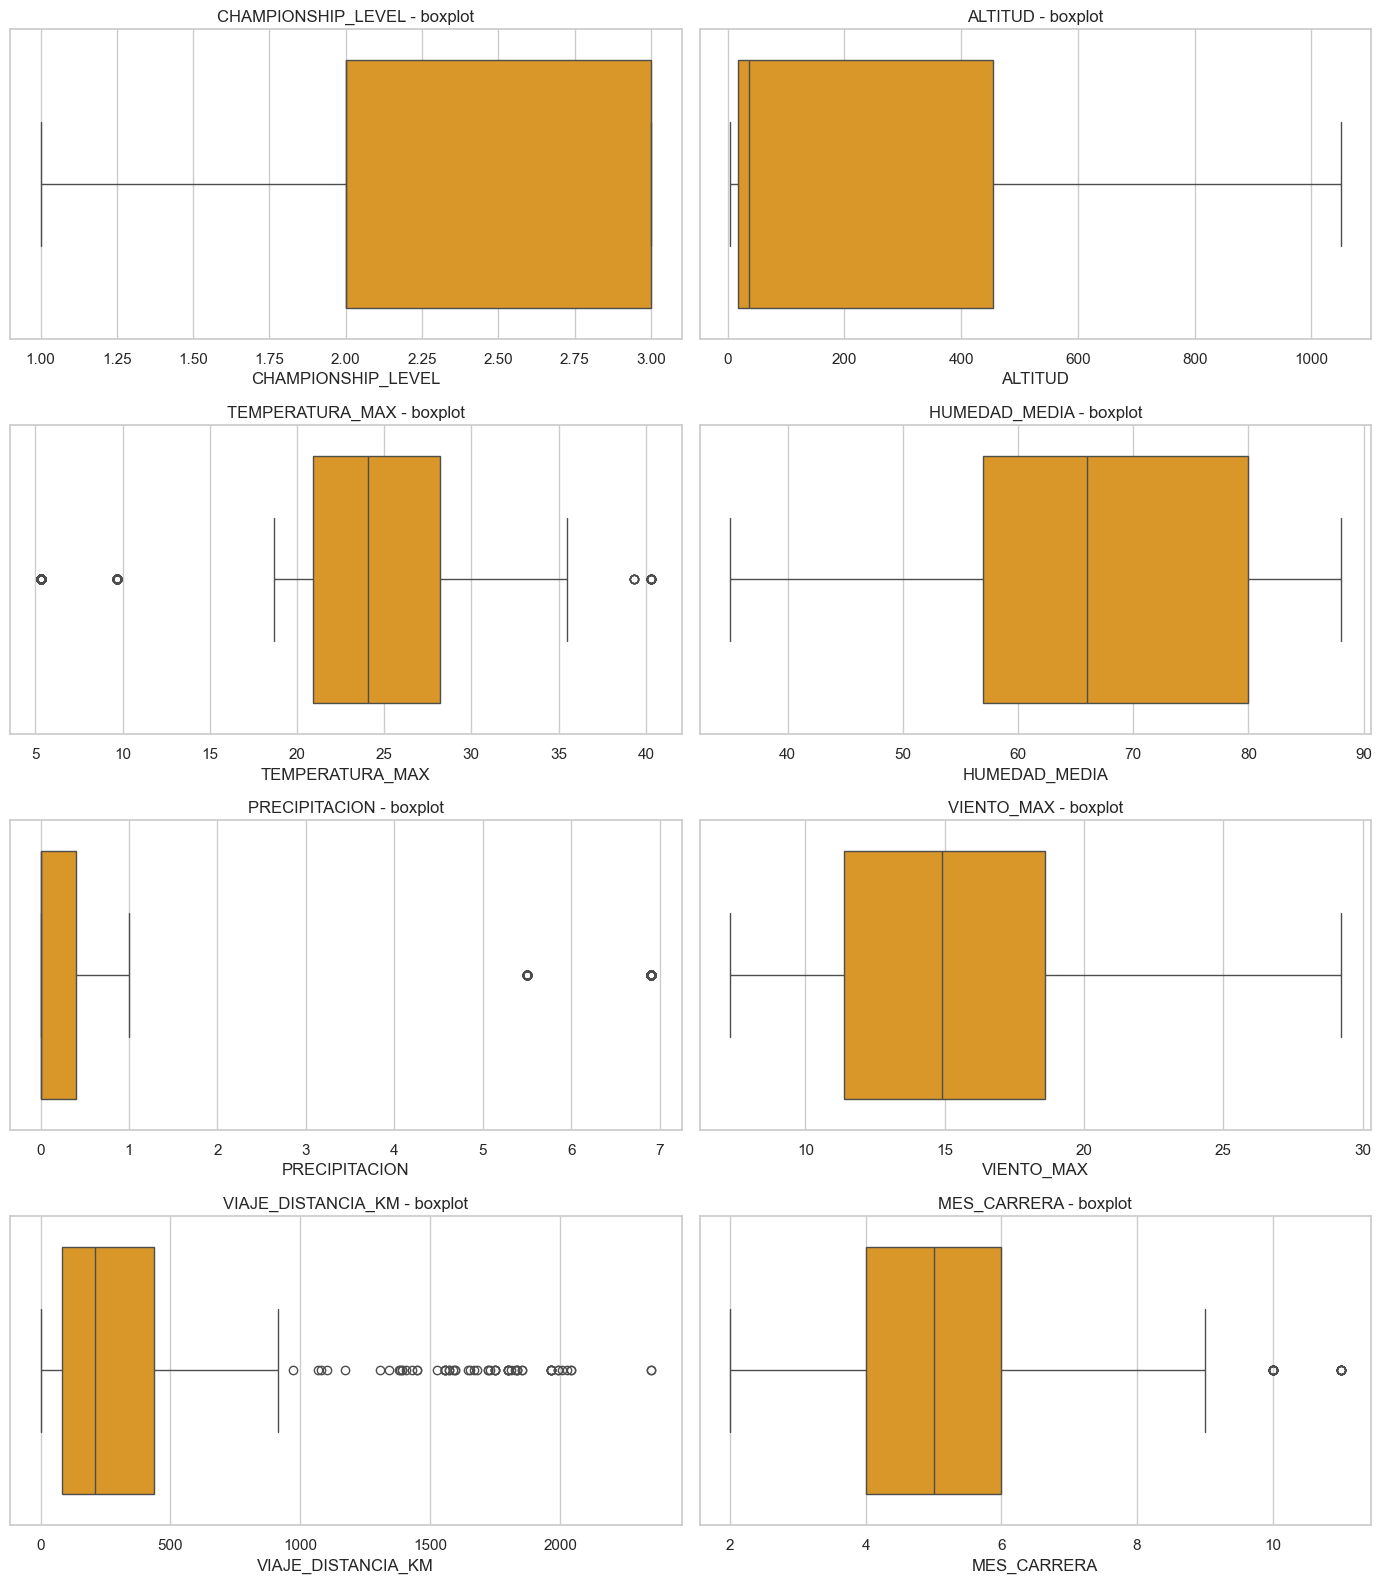

Columnas categóricas útiles para train: ['ATLETA_ID_HASH', 'CLUB', 'GGEE', 'IS_EXTREME_HEAT', 'IS_WET_RACE', 'ES_LOCAL']


C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Temp\ipykernel_3928\3225576906.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette='viridis')
C:\Users\mario\AppData\Local\Te

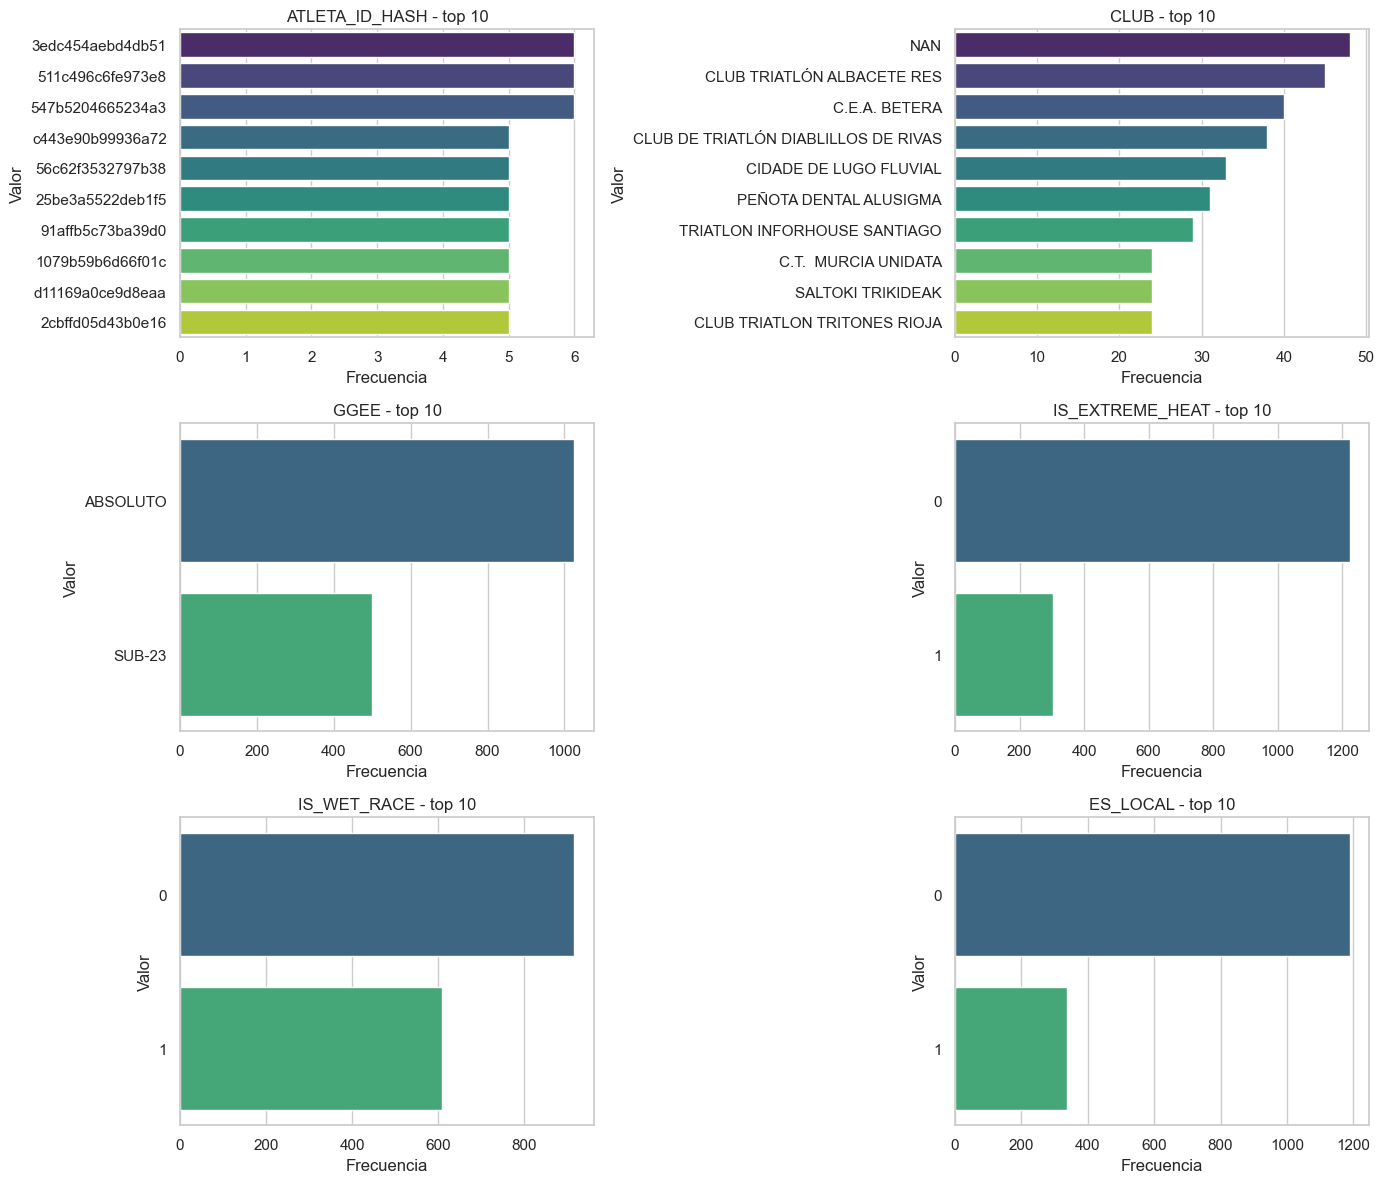

In [17]:
train_path = DATA_DIR / 'trm_2025_azure_automl.csv'
print('Ruta dataset entrenamiento:', train_path)

if train_path.exists():
    df_train = pd.read_csv(train_path)
    print('Shape train:', df_train.shape)
    display(df_train.head())

    print('--- Tipos de columnas ---')
    display(df_train.dtypes.to_frame('dtype').T)

    print('--- Resumen de nulos ---')
    train_missing = pd.DataFrame({
        'nulos': df_train.isna().sum(),
        'pct_nulos': (df_train.isna().mean() * 100).round(2),
        'tipo': df_train.dtypes.astype(str)
    }).sort_values('pct_nulos', ascending=False)
    display(train_missing)

    print('--- Duplicados ---')
    print('Filas duplicadas:', int(df_train.duplicated().sum()))

    train_numeric = relevant_numeric_columns(df_train)
    print('Columnas numéricas útiles para train:', train_numeric)

    # Priorizar target y variables típicamente relevantes si existen
    target_candidates = ['puntos', 'puesto', 'descalificado', 'tiempo_total', 'tiempo', 'minutes']
    target_cols = [c for c in train_numeric if c in target_candidates]
    other_cols = [c for c in train_numeric if c not in target_cols]
    train_corr_cols = target_cols + other_cols[:max(0, 25 - len(target_cols))]

    if len(train_corr_cols) >= 2:
        print('Columnas para correlación del train:', train_corr_cols)
        plot_correlation_heatmap(df_train, train_corr_cols, 'Train / features de entrenamiento', method='spearman', top_pairs_threshold=0.5)
    else:
        print('No hay suficientes columnas numéricas útiles para la correlación del train.')

    # Distribuciones rápidas de algunas variables numéricas del train
    plot_numeric_overview(df_train, train_numeric, 'Train', max_cols=8)

    # Categóricas más útiles
    train_cats = [c for c in categorical_columns(df_train, max_unique=12) if c not in train_numeric]
    print('Columnas categóricas útiles para train:', train_cats)
    plot_categorical_overview(df_train, train_cats, 'Train', max_cols=6, top_n=10)

    # Señal útil para modelado: columnas con demasiados nulos
    high_nulls = train_missing[train_missing['pct_nulos'] >= 30]
    if not high_nulls.empty:
        print('Columnas con >=30% de nulos (candidatas a revisar/eliminar):')
        display(high_nulls)
else:
    df_train = pd.DataFrame()
    print('No existe el archivo de entrenamiento todavía. Ejecuta primero el pipeline de features.')

## 11. Conclusiones

- El EDA útil para modelar es el del dataset final de entrenamiento, porque ahí ya están las variables realmente disponibles para el modelo.
- Hay una relación muy fuerte entre `RECENT_AVG_PUNTOS`, `HIST_AVG_PUNTOS`, `HIST_MAX_PUNTOS` y `HIST_COUNT_PRUEBAS`; esto indica multicolinealidad y obliga a no meterlas todas sin criterio.
- `PUESTO_TARGET` y `PUNTOS_TARGET` están fuertemente relacionados, así que hay que definir claramente cuál será el target final y evitar usar el otro como feature.
- Las variables de clima, distancia y fatiga aportan señal interpretable, pero no parecen dominar por sí solas; su valor está en combinarse con el historial del atleta.
- `ATLETA_ID_HASH` y `CLUB` sirven para trazabilidad o análisis agrupado, pero no deberían entrar al modelo como variables directas sin tratamiento porque tienen alta cardinalidad y poco significado ordinal.
- El dataset está limpio en nulos y sin duplicados, así que el siguiente cuello de botella no es la calidad básica sino seleccionar bien las features y evitar leakage.
- Mi lectura final es que el material ya está suficientemente maduro para pasar a una fase de selección de variables y entrenamiento; ahora toca simplificar y no seguir añadiendo gráficas por añadir.

## 9. Siguientes pasos

Cuando este EDA esté validado, el siguiente paso será cerrar la limpieza final, documentar hallazgos y preparar la base para el Sprint 2.